# PGCB hourly load forecasting, v3 (revision after the professor's review)

One shared pipeline for **all** models, horizons, feature sets and test years, so every new experiment uses the same split, preprocessing and seeds.

**How to run (same idea as before).** Set `HORIZON` in the config cell (`24`, `168`, `720`, or `"DA"` for the fixed-issue day-ahead forecast) and run the notebook top to bottom. Or set `HORIZONS = [24, 168, 720, "DA"]` to do everything in one go. Finished runs are saved and skipped on re-run, so a Kaggle restart loses nothing.

| Step | Cell | Checklist item |
|---|---|---|
| 1 | Data audit: outages, imputation fingerprints, holiday fix (Eid), NASA POWER grid | M7, M9 |
| 2 | (optional) equal tuning budget for every neural model | M6 |
| 3 | Main comparison: M1–M8 + baselines, 5 seeds, 3 rolling test years | M2, M5 |
| 4 | Ablation of M7 (graph vs MLP vs no station input, locality bias) and M2/M5 with station input | M1 |
| 5 | Long-lag feature switch at 168 h and 720 h | M3 |
| 6 | Evaluation tables, MCS, DM vs strongest baseline, DM p-value heatmaps, figures | M4, M5, M6, should-do |
| 7 | Grouped permutation importance, Eid and load-shedding analysis | M8, M7 |
| 8 | Parameter counts at every H, software / GPU versions, reproducibility statement | M9 |

The first code cell writes `pgcb_lib.py` (the whole pipeline). Everything else imports it.

In [3]:
%%writefile pgcb_lib.py
"""
PGCB multi-horizon hourly load forecasting -- shared pipeline (v3, revision for the IEEE submission).

One frozen pipeline is shared by every model, horizon, feature set and test year, so results stay
comparable (professor's rule: same split, preprocessing and seeds for every experiment).

Sections
  0  config and helpers
  1  data loading, data-quality / leakage report (checklist M7)
  2  calendar + holiday fix (Eid etc.), weather and demand features (M3 long-lag switch)
  3  samples, chronological / rolling-origin split, fixed-issue day-ahead (M4, M5)
  4  neural models M1-M8, ablations (M1), neural baselines (M2)
  5  tree / linear / naive baselines (M2)
  6  training, ensembling, tuning budget (M6)
  7  metrics, operational metrics (peak, daily energy, evening peak), prediction intervals incl.
     adaptive conformal (M6), DM tests with the ranking loss, Model Confidence Set (M5)
  8  grouped permutation importance, Eid and load-shedding analyses (M8)
  9  result collection, evaluation tables, figures, reproducibility info (M9)
"""
import os, sys, time, math, json, random, copy, warnings, platform, heapq, bisect, glob, pickle
from dataclasses import dataclass, asdict, replace
from itertools import combinations

import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

warnings.filterwarnings("ignore")

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    HAS_TORCH = True
except ImportError:          # lets the data / baseline / evaluation parts run without PyTorch
    HAS_TORCH = False


# =====================================================================================
# 0. CONFIG AND HELPERS
# =====================================================================================
@dataclass
class Config:
    horizon: object = 24            # 24, 168, 720, or "DA" (fixed issue time 10:00 on D-1 -> all hours of D)
    long_feats: object = "auto"     # "auto" = on only for H > 168 (old behaviour); True / False to force (M3)
    seq_len: int = 168
    val_days: int = 365             # M6: validation now spans all seasons (was 180 days, Sep-Mar)
    test_days: int = 365
    test_end: object = None         # None = last timestamp in the data; else e.g. "2025-03-10 21:00" (M5)
    seeds: tuple = (43, 44, 45, 46, 47)   # M5: 5 seeds (set 10 for the final run if time allows)
    max_epochs: int = 100
    patience: int = 12
    epoch_frac: float = 0.1
    input_noise: float = 0.05
    batch_size: int = 256
    holiday_fix: bool = True        # M7: add Eid / Christmas, recompute days-since/until holiday
    eid_break: tuple = (-3, 4)      # days around Eid flagged as the multi-day Eid break
    exclude_outage_train: bool = True   # M7: drop suspected outage hours from TRAIN targets only
    outage_ratio: float = 0.6       # hour < 60 % of its +-7-day same-hour median -> suspected outage
    issue_hour: int = 10            # M4: day-ahead issue time
    out_root: str = "results_v3"
    run_audit: bool = True
    n_boot: int = 1000
    smoke: bool = False             # quick pipeline check (1 seed, 2 epochs, short val/test)

    def __post_init__(self):
        if self.smoke:
            self.seeds, self.max_epochs, self.patience = (43,), 2, 2
            self.val_days, self.test_days, self.n_boot = 14, 28, 50


DEFAULT_HP = dict(
    lr=3e-4, weight_decay=1e-2, cnn_filters=64, cnn_dropout=0.3, d_model=128, rnn_layers=2, rnn_dropout=0.3,
    head_hidden=128, head_dropout=0.4, known_dim=64, n_heads=4, n_layers=2, ff_dim=256, tf_dropout=0.2,
    gnn_hid=16, gnn_out=32, lb_band=24, lb_tau=6.0, lb_alpha=0.5, patch_len=12, patch_stride=6,
    input_noise=0.05)

STATIONS = ["BAR", "CTG", "DHA", "KHU", "MYM", "RAJ", "RAN", "SYL"]
WVARS = ["T2M", "RH2M", "WS10M", "PS", "PRECTOTCORR", "PSC", "WSC"]
STATION_NAMES = {"BAR": "Barishal", "CTG": "Chattogram", "DHA": "Dhaka", "KHU": "Khulna",
                 "MYM": "Mymensingh", "RAJ": "Rajshahi", "RAN": "Rangpur", "SYL": "Sylhet"}
# Coordinates used for the graph prior. M9: replace with the exact points you entered in NASA POWER.
STATION_COORDS = {"BAR": (22.70, 90.37), "CTG": (22.36, 91.78), "DHA": (23.81, 90.41),
                  "KHU": (22.85, 89.54), "MYM": (24.75, 90.40), "RAJ": (24.37, 88.60),
                  "RAN": (25.74, 89.25), "SYL": (24.90, 91.87)}
scols = lambda v: [f"{v}_{s}" for s in STATIONS]


def is_da(h):
    return isinstance(h, str) and h.upper() == "DA"


def max_lead(cfg):
    return (24 - cfg.issue_hour) + 23 if is_da(cfg.horizon) else int(cfg.horizon)


def long_on(cfg):
    if cfg.long_feats == "auto":
        return (not is_da(cfg.horizon)) and int(cfg.horizon) > 168
    return bool(cfg.long_feats)


def setting_tag(cfg):
    tag = "HDA" if is_da(cfg.horizon) else f"H{int(cfg.horizon)}"
    if cfg.long_feats != "auto":
        tag += "_longON" if cfg.long_feats else "_longOFF"
    return tag


def fold_tag(cfg):
    return "last" if cfg.test_end is None else "end" + pd.Timestamp(cfg.test_end).strftime("%Y%m%d")


def set_seed(s):
    random.seed(s); np.random.seed(s)
    if HAS_TORCH:
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)


def get_device():
    if not HAS_TORCH:
        return None
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


class Audit:
    def __init__(self):
        self.report = {}

    def chk(self, name, cond, verbose=True):
        self.report[name] = bool(cond)
        if verbose or not cond:
            print(f"  [{'PASS' if cond else 'FAIL'}] {name}")
        return bool(cond)

    def failed(self):
        return [k for k, v in self.report.items() if v is False]


# =====================================================================================
# 1. DATA LOADING + DATA-QUALITY REPORT (M7)
# =====================================================================================
CSV_NAMES = ["PGCB_Demand_With_Weather and Holidays.csv"]


def find_csv(path=None):
    if path and os.path.exists(path):
        return path
    cands = []
    for n in CSV_NAMES:
        cands += ["/kaggle/input/datasets/madinavabna/pgcb-data/" + n, n, "/mnt/user-data/uploads/" + n]
    for c in cands:
        if os.path.exists(c):
            return c
    for root, _, files in os.walk("/kaggle/input"):
        for n in CSV_NAMES:
            if n in files:
                return os.path.join(root, n)
    raise FileNotFoundError("PGCB csv not found. Attach the dataset or pass its path.")


def load_data(path=None):
    data = pd.read_csv(find_csv(path))
    data["datetime"] = pd.to_datetime(data["Date"].astype(str) + " " + data["Time"].astype(str))
    data = data.sort_values("datetime").reset_index(drop=True)
    assert not data["datetime"].duplicated().any(), "duplicate timestamps"
    assert data["Sequence_ID"].is_monotonic_increasing, "Sequence_ID not chronological"
    assert np.isfinite(data["Demand"].to_numpy(float)).all() and (data["Demand"] > 0).all()
    for sid, g in data.groupby("Sequence_ID"):
        assert (g["datetime"].diff().dropna() == pd.Timedelta("1h")).all(), f"gap inside sequence {sid}"
    return data


def same_hour_ratio(data, end_time=None, win_days=15):
    """Demand / median of the same hour over +-7 days. Uses only rows before end_time, so flags
    computed for training never look into validation or test data."""
    d = data[["datetime", "Demand"]]
    if end_time is not None:
        d = d[d["datetime"] < pd.Timestamp(end_time)]
    P = d.assign(date=d["datetime"].dt.normalize(), hour=d["datetime"].dt.hour) \
         .pivot_table(index="date", columns="hour", values="Demand")
    P = P.reindex(pd.date_range(P.index.min(), P.index.max(), freq="D"))
    med = P.rolling(win_days, center=True, min_periods=5).median()
    R = (P / med).stack()
    key = pd.MultiIndex.from_arrays([data["datetime"].dt.normalize(), data["datetime"].dt.hour])
    return pd.Series(R.reindex(key).to_numpy(), index=data.index)


def _runs(mask):
    """start/end index pairs of consecutive True runs."""
    m = np.r_[False, mask, False].astype(int)
    s, e = np.where(np.diff(m) == 1)[0], np.where(np.diff(m) == -1)[0] - 1
    return list(zip(s, e))


def data_quality_report(data, out_dir, fold_test_windows=None, ratio_thr=0.6):
    """M7: outage candidates (incl. the 1,759 MW minimum), imputation fingerprints, holiday counts.
    Report only; nothing here changes the test targets."""
    os.makedirs(out_dir, exist_ok=True)
    D = data["Demand"].to_numpy(float)
    dts = data["datetime"]

    desc = pd.Series({"rows": len(data), "start": dts.iloc[0], "end": dts.iloc[-1],
                      "sequences": data["Sequence_ID"].nunique(), "min MW": D.min(),
                      "min at": dts.iloc[D.argmin()], "max MW": D.max(), "max at": dts.iloc[D.argmax()],
                      "mean MW": D.mean(), "sd MW": D.std()})
    desc.to_csv(f"{out_dir}/dataset_description.csv")

    ratio = same_hour_ratio(data)            # full data, reporting only
    flag = (ratio < ratio_thr).to_numpy()
    ev = []
    for s, e in _runs(flag):
        seg = slice(s, e + 1)
        ev.append({"start": dts.iloc[s], "end": dts.iloc[e], "hours": e - s + 1,
                   "min MW": D[seg].min(), "min ratio to same-hour median": float(np.nanmin(ratio.iloc[seg])),
                   "split": "see fold windows"})
    events = pd.DataFrame(ev)
    if fold_test_windows and len(events):
        def which(t):
            for name, (a, b) in fold_test_windows.items():
                if a <= t <= b:
                    return f"TEST {name}"
            return "train/val only"
        events["split"] = events["start"].map(which)
    events.to_csv(f"{out_dir}/suspected_outage_events.csv", index=False)

    lowest = data.nsmallest(20, "Demand")[["datetime", "Demand"]].copy()
    lowest["ratio_to_same_hour_median"] = ratio.loc[lowest.index].values
    lowest.to_csv(f"{out_dir}/lowest_20_hours.csv", index=False)

    eq = np.r_[False, np.diff(D) == 0]
    lin = np.r_[False, False, np.abs(np.diff(D, 2)) < 1e-9]
    fp = []
    for name, m, min_len in (("repeated value (>=3 equal hours)", eq, 2), ("linear segment (>=4 collinear hours)", lin, 2)):
        for s, e in _runs(m):
            if e - s + 1 >= min_len:
                fp.append({"type": name, "start": dts.iloc[max(s - 1, 0)], "end": dts.iloc[e], "hours": e - s + 2})
    fp = pd.DataFrame(fp)
    if len(fp):
        fp["year"] = pd.to_datetime(fp["start"]).dt.year
        if fold_test_windows:
            fp["in_test_of"] = fp["start"].map(lambda t: ",".join(n for n, (a, b) in fold_test_windows.items() if a <= t <= b))
    fp.to_csv(f"{out_dir}/imputation_fingerprints.csv", index=False)

    print("\n=== DATA QUALITY (M7) ===")
    print(desc.to_string())
    print(f"\nSuspected outage events (hour < {ratio_thr:.0%} of same-hour +-7-day median): {len(events)}")
    if len(events):
        print(events.sort_values("min MW").head(15).to_string(index=False))
    if len(fp):
        print("\nImputation fingerprints by type and year:")
        print(fp.groupby(["type", "year"]).size().unstack(0).fillna(0).astype(int).to_string())
        if "in_test_of" in fp:
            print("Fingerprints inside test windows:", int((fp["in_test_of"] != "").sum()))
    return dict(description=desc, events=events, lowest=lowest, fingerprints=fp)


# =====================================================================================
# 2. FEATURES
# =====================================================================================
_EPOCH = 1948439.5


def _greg_to_jd(y, m, d):
    a = (14 - m) // 12
    yy, mm = y + 4800 - a, m + 12 * a - 3
    return d + (153 * mm + 2) // 5 + 365 * yy + yy // 4 - yy // 100 + yy // 400 - 32045 - 0.5


def _isl_to_jd(y, m, d):
    return d + math.ceil(29.5 * (m - 1)) + (y - 1) * 354 + math.floor((3 + 11 * y) / 30) + _EPOCH - 1


def islamic_month_day(ts):
    """Tabular (arithmetic) Islamic calendar; within about +-1 day of the Bangladesh moon-sighting date."""
    jd = _greg_to_jd(ts.year, ts.month, ts.day)
    y = math.floor((30 * (jd - _EPOCH) + 10646) / 10631)
    m = min(12, math.ceil((jd - (29 + _isl_to_jd(y, 1, 1))) / 29.5) + 1)
    return m, int(jd - _isl_to_jd(y, m, 1) + 1)


def holiday_calendar(data, cfg, extra_csv=None):
    """M7 holiday fix. The raw flag holds only the 7 fixed-date national days per year; Eid-ul-Fitr,
    Eid-ul-Adha and Christmas are missing. Holidays are announced in advance, so using them as
    target-hour features is not leakage. Optional extra_csv (column 'date') adds the official
    gazette list (Durga Puja, Buddha Purnima, Ashura, election days, extended Eid breaks ...)."""
    days = pd.date_range(data["datetime"].min().normalize() - pd.Timedelta(days=400),
                         data["datetime"].max().normalize() + pd.Timedelta(days=400), freq="D")
    md = {d: islamic_month_day(d) for d in days}
    fitr = [d for d in days if md[d] == (10, 1)]
    adha = [d for d in days if md[d] == (12, 10)]
    eid = np.array(sorted(fitr + adha), dtype="datetime64[D]")

    raw_hol = set(data.loc[data["Holiday_Category"].astype(int) == 2, "datetime"].dt.normalize())
    fixed_md = {(d.month, d.day) for d in raw_hol} | {(12, 25)}
    hol = {d for d in days if (d.month, d.day) in fixed_md}
    for e in fitr + adha:                                    # core public holidays: Eid-1 .. Eid+2
        hol |= {e + pd.Timedelta(days=k) for k in range(-1, 3)}
    if extra_csv and os.path.exists(extra_csv):
        hol |= set(pd.to_datetime(pd.read_csv(extra_csv)["date"]).dt.normalize())
    hol_arr = np.array(sorted(hol), dtype="datetime64[D]")

    dn = data["datetime"].dt.normalize().to_numpy().astype("datetime64[D]")
    i_next = np.searchsorted(hol_arr, dn, side="left")
    i_prev = np.searchsorted(hol_arr, dn, side="right") - 1
    until = (hol_arr[np.clip(i_next, 0, len(hol_arr) - 1)] - dn).astype(int)
    since = (dn - hol_arr[np.clip(i_prev, 0, len(hol_arr) - 1)]).astype(int)
    j = np.clip(np.searchsorted(eid, dn), 1, len(eid) - 1)
    d_next, d_prev = (eid[j] - dn).astype(int), (dn - eid[j - 1]).astype(int)
    signed = np.where(d_prev <= d_next, d_prev, -d_next)    # + after Eid, - before Eid

    out = pd.DataFrame(index=data.index)
    out["IsPublicHoliday"] = np.isin(dn, hol_arr).astype(float)
    out["Days_Since_Holiday"] = since.astype(float)
    out["Days_Until_Holiday"] = until.astype(float)
    out["IsEidBreak"] = ((signed >= cfg.eid_break[0]) & (signed <= cfg.eid_break[1])).astype(float)
    out["Eid_Signed"] = np.clip(signed, -15, 15) / 15.0
    out["Eid_Decay"] = np.exp(-np.abs(signed) / 3.0)
    return out, pd.DataFrame({"Eid-ul-Fitr": pd.Series(fitr), "Eid-ul-Adha": pd.Series(adha)})


BASE_LAGS = [1, 2, 3, 24, 48, 72, 168, 336, 504, 672]
LONG_LAGS = [1440, 8760]


def demand_features(df, H, long_feats, is_known):
    """Unchanged logic from v2; long_feats is now an explicit switch (M3) instead of H > 168."""
    roll = [24, 72, 168] + ([720] if long_feats else [])
    ewm = [6, 24, 72, 168] + ([720] if long_feats else [])
    sid = df["Sequence_ID"]
    g = df.groupby("Sequence_ID", sort=False)["Demand"]
    lev, oth = {}, {}
    extra = [k for k in LONG_LAGS if k > H] if (long_feats and is_known) else []
    for k in sorted(set([H] + [k for k in BASE_LAGS if k > H] + extra)):
        lev[f"lag{k}"] = np.log(g.shift(k))
    base = g.shift(H)
    lbase = np.log(base)
    gb, gl = base.groupby(sid, sort=False), lbase.groupby(sid, sort=False)
    for w in roll:
        lev[f"rmean{w}"] = np.log(gb.transform(lambda s, w=w: s.rolling(w).mean()))
        oth[f"lstd{w}"] = gl.transform(lambda s, w=w: s.rolling(w).std())
    for hl in ewm:
        lev[f"ewm{hl}"] = np.log(gb.transform(lambda s, hl=hl: s.ewm(halflife=hl, adjust=False).mean()))
    k0 = math.ceil(H / 24)
    lev["sameHour7d"] = np.log(pd.concat([g.shift(24 * (k0 + j)) for j in range(7)], axis=1).mean(axis=1, skipna=False))
    m0 = max(math.ceil(H / 168) - 1, 0)
    lev["sameHourDow4w"] = np.log(pd.concat([g.shift(168 * (m0 + m)) for m in range(1, 5)], axis=1).mean(axis=1, skipna=False))
    if "lag8760" in lev:
        has_ly = lev["lag8760"].notna()
        lev["lag8760"] = lev["lag8760"].fillna(lev["sameHour7d"])
        oth["has_lag8760"] = has_ly.astype(float)
    for d in (1, 24, 72):
        oth[f"diff{d}"] = lbase - gl.shift(d)
    return pd.DataFrame(lev, index=df.index), pd.DataFrame(oth, index=df.index)


CAL_COLS = ["Hour_sin", "Hour_cos", "DoW_sin", "DoW_cos", "Month_sin", "Month_cos", "DoY_sin", "DoY_cos"]
PEAK_COLS = ["IsMorningPeak", "IsEveningPeak", "IsNight"]
HOL_COLS = ["IsWeekend", "IsPublicHoliday", "IsRamadan", "Ramadan_Day",
            "Days_Since_Holiday", "Days_Until_Holiday", "Hol_Since_Decay", "Hol_Until_Decay"]
EID_COLS = ["IsEidBreak", "Eid_Signed", "Eid_Decay"]
WAGG_COLS = ["T2M_mean", "T2M_max", "T2M_min", "T2M_range", "RH2M_mean", "WS10M_mean", "PS_mean",
             "PRECTOTCORR_mean", "CDH", "DewPoint", "T2M_roll3", "T2M_roll6", "T2M_roll24",
             "CDH_evening", "CDH_morning"]
RAW_ALL = [f"{v}_{s}" for s in STATIONS for v in WVARS]
RAW_SMALL = ["T2M_DHA", "RH2M_DHA"]


def feature_group(name):
    """M8 grouped permutation importance: calendar / holiday (incl. Ramadan, Eid) / weather / demand."""
    n = name.split("_", 1)[1] if name[:2] in ("w_", "t_") else name
    if name == "logD" or name[:2] in ("w_", "t_"):
        return "demand history"
    if n in WAGG_COLS or n in RAW_ALL:
        return "weather"
    if n in HOL_COLS or n in EID_COLS:
        return "holiday"
    return "calendar"     # sin/cos, hour/day one-hot, peak-period indicators


class FeatureSet:
    """All features for one (lead definition, long-feature switch, holiday fix). Independent of the fold."""

    def __init__(self, raw, cfg, extra_holidays_csv=None, audit=True):
        t0 = time.time()
        self.cfg = cfg
        data = raw.copy()
        dt = data["datetime"].dt
        data["Hour"], data["DoW"] = dt.hour, dt.dayofweek
        for name, val, period in [("Hour", dt.hour, 24), ("DoW", dt.dayofweek, 7),
                                  ("Month", dt.month, 12), ("DoY", dt.dayofyear, 365.25)]:
            data[f"{name}_sin"] = np.sin(2 * np.pi * val / period)
            data[f"{name}_cos"] = np.cos(2 * np.pi * val / period)
        data["IsMorningPeak"] = data["Hour"].between(7, 10).astype(float)
        data["IsEveningPeak"] = data["Hour"].between(18, 21).astype(float)
        data["IsNight"] = data["Hour"].between(0, 5).astype(float)

        if cfg.holiday_fix:
            hc, self.eid_table = holiday_calendar(data, cfg, extra_holidays_csv)
            for c in hc.columns:
                data[c] = hc[c]
            data["IsWeekend"] = data["DoW"].isin([4, 5]).astype(float)       # Friday, Saturday
        else:
            cat = data["Holiday_Category"].astype(int)
            data["IsWeekend"] = (cat == 1).astype(float)
            data["IsPublicHoliday"] = (cat == 2).astype(float)
            self.eid_table = None
        data["Hol_Since_Decay"] = np.exp(-data["Days_Since_Holiday"] / 3.0)
        data["Hol_Until_Decay"] = np.exp(-data["Days_Until_Holiday"] / 3.0)

        dn = data["datetime"].dt.normalize()
        md = {d: islamic_month_day(d) for d in dn.drop_duplicates()}
        data["IsRamadan"] = dn.map(lambda d: float(md[d][0] == 9))
        data["Ramadan_Day"] = dn.map(lambda d: md[d][1] / 30.0 if md[d][0] == 9 else 0.0)
        data["DayType"] = np.where(data["IsPublicHoliday"] == 1, "Public holiday",
                                   np.where(data["IsWeekend"] == 1, "Weekend (Fri/Sat)", "Working day"))
        if not cfg.holiday_fix:
            data["IsEidBreak"] = 0.0

        data["T2M_mean"] = data[scols("T2M")].mean(axis=1)
        data["T2M_max"] = data[scols("T2M")].max(axis=1)
        data["T2M_min"] = data[scols("T2M")].min(axis=1)
        data["T2M_range"] = data["T2M_max"] - data["T2M_min"]
        for v in ("RH2M", "WS10M", "PS", "PRECTOTCORR"):
            data[f"{v}_mean"] = data[scols(v)].mean(axis=1)
        data["CDH"] = np.maximum(data["T2M_mean"] - 24.0, 0.0)
        data["DewPoint"] = data["T2M_mean"] - (100 - data["RH2M_mean"]) / 5.0
        gT = data.groupby("Sequence_ID", sort=False)["T2M_mean"]
        for w in (3, 6, 24):
            data[f"T2M_roll{w}"] = gT.transform(lambda s, w=w: s.rolling(w, min_periods=1).mean())
        data["CDH_evening"] = data["CDH"] * data["IsEveningPeak"]
        data["CDH_morning"] = data["CDH"] * data["IsMorningPeak"]

        self.long = long_on(cfg)
        self.h_known = max_lead(cfg)
        lev_w, oth_w = demand_features(data, 1, self.long, False)
        lev_w, oth_w = lev_w.add_prefix("w_"), oth_w.add_prefix("w_")
        lev_t, oth_t = demand_features(data, self.h_known, self.long, True)
        lev_t, oth_t = lev_t.add_prefix("t_"), oth_t.add_prefix("t_")
        LEV = pd.concat([np.log(data["Demand"]).rename("logD"), lev_w, lev_t], axis=1)

        hol_cols = HOL_COLS + (EID_COLS if cfg.holiday_fix else [])
        flag_cols = PEAK_COLS + hol_cols
        onehot = pd.concat([
            pd.get_dummies(data["Hour"], prefix="Hr").astype(float).reindex(columns=[f"Hr_{h}" for h in range(24)], fill_value=0.0),
            pd.get_dummies(data["DoW"], prefix="Dw").astype(float).reindex(columns=[f"Dw_{d}" for d in range(7)], fill_value=0.0)], axis=1)
        OTH = pd.concat([data[CAL_COLS + flag_cols + WAGG_COLS + RAW_ALL], onehot, oth_w, oth_t], axis=1)
        OTH = OTH.loc[:, ~OTH.columns.duplicated()]

        self.win_lev = ["logD"] + list(lev_w.columns)
        self.known_lev = list(lev_t.columns)
        base_oth = CAL_COLS + flag_cols + WAGG_COLS
        self.win_oth = {False: base_oth + RAW_SMALL + list(oth_w.columns),      # 62 channels (65 with long feats)
                        True: base_oth + RAW_ALL + list(oth_w.columns)}         # +54 -> 116 (119)
        self.known_oth = CAL_COLS + flag_cols + list(onehot.columns) + list(oth_t.columns)

        if audit and cfg.run_audit:
            self._audit_causality(data, lev_w, oth_w, lev_t, oth_t)

        keep = (LEV.notna().all(axis=1) & OTH.notna().all(axis=1)).to_numpy()
        self.n_dropped = int((~keep).sum())
        self.data = data[keep].reset_index(drop=True)
        self.LEV = LEV[keep].reset_index(drop=True)
        self.OTH = OTH[keep].reset_index(drop=True)
        assert np.isfinite(self.LEV.to_numpy(np.float64)).all() and np.isfinite(self.OTH.to_numpy(np.float64)).all()
        for sid, g in self.data.groupby("Sequence_ID"):
            assert (g["datetime"].diff().dropna() == pd.Timedelta("1h")).all()

        hour = self.data["datetime"].dt.hour.to_numpy()
        if is_da(cfg.horizon):
            self.lead = ((24 - cfg.issue_hour) + hour).astype(np.int64)        # 14 .. 37 h
        else:
            self.lead = np.full(len(self.data), int(cfg.horizon), dtype=np.int64)
        print(f"[features] {setting_tag(cfg)} long_feats={self.long} holiday_fix={cfg.holiday_fix} | "
              f"rows {len(self.data):,} (dropped {self.n_dropped} warm-up) | window {len(self.win_lev) + len(self.win_oth[False])}"
              f"/{len(self.win_lev) + len(self.win_oth[True])} ch | known {len(self.known_lev) + len(self.known_oth)} | {time.time() - t0:.0f}s")

    def _audit_causality(self, data, lev_w, oth_w, lev_t, oth_t):
        A = Audit()
        H = self.h_known
        pos = data.groupby("Sequence_ID").cumcount().to_numpy()
        cand = np.where(pos >= 700 + H)[0]
        c = int(cand[int(0.9 * len(cand))])
        same = lambda a, b, upto: bool(np.allclose(a.iloc[:upto + 1].to_numpy(float), b.iloc[:upto + 1].to_numpy(float),
                                                   rtol=1e-9, atol=1e-9, equal_nan=True))
        base = data[["Sequence_ID", "Demand"]]
        d2 = base.copy(); d2.loc[d2.index > c - H, "Demand"] = np.nan
        lw, ow = demand_features(d2, 1, self.long, False)
        lt, ot = demand_features(d2, H, self.long, True)
        d3 = base.copy(); d3.loc[d3.index >= c - H, "Demand"] = np.nan
        l3, _ = demand_features(d3, H, self.long, True)
        print(f"\n[audit] feature causality at row {c} ({data['datetime'].iloc[c]}), known-feature lag H={H}")
        A.chk("window demand features use only rows <= reference", same(lev_w, lw.add_prefix("w_"), c - H + 1)
              and same(oth_w, ow.add_prefix("w_"), c - H + 1))
        A.chk("known target-hour demand features use only demand <= t-H", same(lev_t, lt.add_prefix("t_"), c)
              and same(oth_t, ot.add_prefix("t_"), c))
        A.chk("positive control detects injected leakage", not same(lev_t, l3.add_prefix("t_"), c))
        assert not A.failed(), A.failed()
        self.audit = A.report


# =====================================================================================
# 3. SAMPLES AND SPLIT
# =====================================================================================
class Split:
    """Chronological split on targets: [train | val (cfg.val_days) | test (cfg.test_days)] ending at
    cfg.test_end. Earlier test_end values give the rolling-origin folds (M5). Scalers are fitted on
    training rows only. With horizon='DA' every target hour of day D uses origin 10:00 on D-1."""

    def __init__(self, fs, cfg, device=None, verbose=True):
        self.fs, self.cfg = fs, cfg
        data = fs.data
        self.data = data
        self.dts = data["datetime"]
        self._s = self.dts.values.astype("datetime64[s]").astype(np.int64)
        self.D = data["Demand"].to_numpy(np.float64)
        self.lead = fs.lead
        self.sid = data["Sequence_ID"].to_numpy()
        L = cfg.seq_len
        pos = data.groupby("Sequence_ID").cumcount().to_numpy()
        ok = pos >= L - 1 + self.lead
        if cfg.test_end is not None:
            ok &= (self.dts <= pd.Timestamp(cfg.test_end)).to_numpy()
        valid = np.where(ok)[0]
        if is_da(cfg.horizon):                                   # test ends on a complete day
            valid = valid[valid <= valid[self.dts.dt.hour.to_numpy()[valid] == 23][-1]]
        TN, VN = cfg.test_days * 24, cfg.val_days * 24
        self.test_t, self.val_t, train_t = valid[-TN:], valid[-(TN + VN):-TN], valid[:-(TN + VN)]

        self.outage_train = np.zeros(len(data), bool)
        if cfg.exclude_outage_train:
            r = same_hour_ratio(data, end_time=self.dts.iloc[self.val_t[0]]).to_numpy()
            self.outage_train = np.nan_to_num(r, nan=1.0) < cfg.outage_ratio
            bad = self.outage_train[train_t] | self.outage_train[train_t - self.lead[train_t]]
            self.n_outage_excluded = int(bad.sum())
            train_t = train_t[~bad]
        else:
            self.n_outage_excluded = 0
        self.train_t = train_t

        fit_rows = np.arange(self.train_t[-1] + 1)
        self.fit_rows = fit_rows
        self.scaler = StandardScaler().fit(fs.OTH.iloc[fit_rows].to_numpy(np.float64))
        self.OTH_s = np.clip(self.scaler.transform(fs.OTH.to_numpy(np.float64)), -10, 10).astype(np.float32)
        self.LEV = fs.LEV.to_numpy(np.float32)
        iw = fs.LEV.columns.get_loc("w_lag168")
        self.LEV_SCALE = float(np.std(self.LEV[fit_rows, 0] - self.LEV[fit_rows, iw]))
        tr = self.train_t
        self.Y_SCALE = float(np.std(self.LEV[tr, 0] - self.LEV[tr - self.lead[tr], 0]))
        r24 = fit_rows[pos[fit_rows] >= 24]
        self.mase_scale = float(np.mean(np.abs(self.D[r24] - self.D[r24 - 24])))   # in-sample daily naive, same for all H

        ix = lambda names, cols: [list(cols).index(n) for n in names]
        self.win_lev_idx = ix(fs.win_lev, fs.LEV.columns)
        self.known_lev_idx = ix(fs.known_lev, fs.LEV.columns)
        self.win_oth_idx = {s: ix(fs.win_oth[s], fs.OTH.columns) for s in (False, True)}
        self.known_oth_idx = ix(fs.known_oth, fs.OTH.columns)
        self.n_seq = {s: len(self.win_lev_idx) + len(self.win_oth_idx[s]) for s in (False, True)}
        self.n_known = len(self.known_lev_idx) + len(self.known_oth_idx)
        self.seq_names = {s: fs.win_lev + fs.win_oth[s] for s in (False, True)}
        self.known_names = fs.known_lev + fs.known_oth
        self.raw_idx = [len(self.win_lev_idx) + fs.win_oth[True].index(c) for c in RAW_ALL]   # station layout
        self.device = device
        self._torch = None

        self.audit = Audit()
        if cfg.run_audit:
            self._audit(verbose)
        if True:
            sp = lambda t: f"{self.dts.iloc[t[0]]:%Y-%m-%d %H:%M} -> {self.dts.iloc[t[-1]]:%Y-%m-%d %H:%M}"
            print(f"[split {fold_tag(cfg)} {setting_tag(cfg)}] train {len(self.train_t):,} ({sp(self.train_t)}), "
                  f"outage targets excluded {self.n_outage_excluded} | val {len(self.val_t):,} ({sp(self.val_t)}) | "
                  f"test {len(self.test_t):,} ({sp(self.test_t)}) | LEV_SCALE {self.LEV_SCALE:.4f} Y_SCALE {self.Y_SCALE:.4f}")

    def table(self):
        return pd.DataFrame({"split": ["train", "val", "test"],
                             "n": [len(self.train_t), len(self.val_t), len(self.test_t)],
                             "first target": [self.dts.iloc[t[0]] for t in (self.train_t, self.val_t, self.test_t)],
                             "last target": [self.dts.iloc[t[-1]] for t in (self.train_t, self.val_t, self.test_t)]})

    # ---- batches -------------------------------------------------------------------
    def batch_np(self, t, station=False):
        t = np.asarray(t)
        ref = t - self.lead[t]
        rows = (ref - self.cfg.seq_len + 1)[:, None] + np.arange(self.cfg.seq_len)[None, :]
        refv = self.LEV[ref, 0]
        xl = (self.LEV[rows][:, :, self.win_lev_idx] - refv[:, None, None]) / self.LEV_SCALE
        x = np.concatenate([xl, self.OTH_s[rows][:, :, self.win_oth_idx[station]]], axis=-1)
        k = np.concatenate([(self.LEV[t][:, self.known_lev_idx] - refv[:, None]) / self.LEV_SCALE,
                            self.OTH_s[t][:, self.known_oth_idx]], axis=-1)
        y = (self.LEV[t, 0] - refv) / self.Y_SCALE
        return x.astype(np.float32), k.astype(np.float32), y.astype(np.float32)

    def to_mw(self, scaled, t):
        t = np.asarray(t)
        return self.D[t - self.lead[t]] * np.exp(np.asarray(scaled, dtype=np.float64) * self.Y_SCALE)

    def torch_tensors(self):
        if self._torch is None:
            dev = self.device
            T = lambda a: torch.tensor(a, dtype=torch.float32, device=dev)
            LEV_ALL = T(self.LEV)
            self._torch = dict(
                LEV0=LEV_ALL[:, 0].contiguous(), LEV_WIN=LEV_ALL[:, self.win_lev_idx].contiguous(),
                LEV_KNOWN=LEV_ALL[:, self.known_lev_idx].contiguous(),
                OTH_WIN={s: T(self.OTH_s[:, self.win_oth_idx[s]]) for s in (False, True)},
                OTH_KNOWN=T(self.OTH_s[:, self.known_oth_idx]),
                LEAD=torch.as_tensor(self.lead, dtype=torch.long, device=dev),
                AR=torch.arange(self.cfg.seq_len, device=dev))
        return self._torch

    def batch(self, t, station=False):
        """Torch batch (same maths as batch_np, on the GPU)."""
        G = self.torch_tensors()
        ref = t - G["LEAD"][t]
        rows = (ref - self.cfg.seq_len + 1).unsqueeze(1) + G["AR"].unsqueeze(0)
        refv = G["LEV0"][ref]
        xl = (G["LEV_WIN"][rows] - refv[:, None, None]) / self.LEV_SCALE
        x = torch.cat([xl, G["OTH_WIN"][station][rows]], dim=-1)
        k = torch.cat([(G["LEV_KNOWN"][t] - refv[:, None]) / self.LEV_SCALE, G["OTH_KNOWN"][t]], dim=-1)
        y = (G["LEV0"][t] - refv) / self.Y_SCALE
        return x, k, y

    def tensor_idx(self, t):
        return torch.as_tensor(np.asarray(t), dtype=torch.long, device=self.device)

    # ---- audit ---------------------------------------------------------------------
    def _audit(self, verbose):
        A, L, H1 = self.audit, self.cfg.seq_len, 3600
        v = verbose
        for nm, T in (("train", self.train_t), ("val", self.val_t), ("test", self.test_t)):
            ref = T - self.lead[T]
            start = ref - L + 1
            A.chk(f"{nm}: window start inside data", start.min() >= 0, v)
            A.chk(f"{nm}: target = origin + lead hours", np.all(self._s[T] - self._s[ref] == self.lead[T] * H1), v)
            A.chk(f"{nm}: window is {L} contiguous hours ending at origin", np.all(self._s[ref] - self._s[start] == (L - 1) * H1), v)
            A.chk(f"{nm}: window never crosses a sequence boundary", np.all(self.sid[T] == self.sid[start]), v)
            if is_da(self.cfg.horizon):
                A.chk(f"{nm}: DA origin is {self.cfg.issue_hour}:00 on D-1",
                      np.all(self.dts.dt.hour.to_numpy()[ref] == self.cfg.issue_hour)
                      and np.all((self.dts.dt.normalize().to_numpy()[T] - self.dts.dt.normalize().to_numpy()[ref])
                                 == np.timedelta64(1, "D")), v)
        A.chk("split: train < val < test (targets)", self.train_t[-1] < self.val_t[0] and self.val_t[-1] < self.test_t[0], v)
        A.chk("split: val and test hourly-contiguous", (np.diff(self._s[self.val_t]) == H1).all()
              and (np.diff(self._s[self.test_t]) == H1).all() and self._s[self.test_t[0]] - self._s[self.val_t[-1]] == H1, v)
        A.chk("split: train inputs end before validation", (self.train_t - self.lead[self.train_t]).max() < self.val_t[0], v)
        A.chk("split: validation inputs end before test", (self.val_t - self.lead[self.val_t]).max() < self.test_t[0], v)
        A.chk("scaler: fitted on rows up to the last train target only", self.fit_rows[-1] == self.train_t[-1] < self.val_t[0], v)
        A.chk("cleaning: outage exclusion touched train targets only (no val/test target removed)",
              len(self.val_t) == self.cfg.val_days * 24 and len(self.test_t) == self.cfg.test_days * 24, v)
        rng = np.random.default_rng(0)
        for nm, T in (("train", self.train_t), ("test", self.test_t)):
            sub = np.sort(rng.choice(T, size=min(256, len(T)), replace=False))
            x, k, y = self.batch_np(sub)
            ref = sub - self.lead[sub]
            rows = (ref - L + 1)[:, None] + np.arange(L)[None, :]
            A.chk(f"{nm}: logD channel == logD[origin-{L - 1} .. origin]",
                  np.allclose(x[:, :, 0] * self.LEV_SCALE + self.LEV[ref, 0][:, None], self.LEV[rows, 0], atol=1e-4), v)
            A.chk(f"{nm}: target == logD[t]-logD[origin]", np.allclose(y * self.Y_SCALE + self.LEV[ref, 0], self.LEV[sub, 0], atol=1e-4), v)
            if HAS_TORCH and self.device is not None:
                xt, kt, yt = self.batch(self.tensor_idx(sub))
                A.chk(f"{nm}: torch batch == numpy batch", np.allclose(xt.cpu().numpy(), x, atol=1e-5)
                      and np.allclose(kt.cpu().numpy(), k, atol=1e-5), v)
        bad = A.failed()
        print(f"[audit] {sum(A.report.values())} passed, {len(bad)} failed")
        assert not bad, f"leakage/indexing audit FAILED: {bad}"


# =====================================================================================
# 4. NEURAL MODELS
# =====================================================================================
if HAS_TORCH:
    class StridedCNN(nn.Module):
        def __init__(self, n_in, hp):
            super().__init__()
            f = hp["cnn_filters"]
            self.conv1, self.bn1 = nn.Conv1d(n_in, 128, 5, padding=2), nn.BatchNorm1d(128)
            self.conv2, self.bn2 = nn.Conv1d(128, f, 3, padding=1), nn.BatchNorm1d(f)
            self.pool, self.drop = nn.MaxPool1d(2), nn.Dropout(hp["cnn_dropout"])

        def forward(self, x):
            z = self.pool(torch.relu(self.bn1(self.conv1(x.permute(0, 2, 1)))))
            z = self.drop(torch.relu(self.bn2(self.conv2(z))))
            return z.permute(0, 2, 1)

    def make_rnn(cell, bidirectional, hp, n_in=None):
        hidden = hp["d_model"] // 2 if bidirectional else hp["d_model"]
        return cell(n_in or hp["cnn_filters"], hidden, num_layers=hp["rnn_layers"], batch_first=True,
                    dropout=hp["rnn_dropout"], bidirectional=bidirectional)

    def pool_seq(z):
        return torch.cat([z.mean(dim=1), z.max(dim=1).values], dim=1)

    def known_branch(n_known, hp):
        return nn.Sequential(nn.Linear(n_known, 128), nn.ReLU(), nn.Dropout(0.1),
                             nn.Linear(128, hp["known_dim"]), nn.ReLU())

    def make_head(in_dim, hp):
        return nn.Sequential(nn.Linear(in_dim, hp["head_hidden"]), nn.ReLU(), nn.Dropout(hp["head_dropout"]),
                             nn.Linear(hp["head_hidden"], 1))

    class EncoderLayer(nn.Module):
        def __init__(self, d, heads, ff, dropout):
            super().__init__()
            self.h, self.dp = heads, dropout
            self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
            self.qkv, self.proj = nn.Linear(d, 3 * d), nn.Linear(d, d)
            self.ff = nn.Sequential(nn.Linear(d, ff), nn.GELU(), nn.Dropout(dropout), nn.Linear(ff, d))
            self.drop = nn.Dropout(dropout)

        def forward(self, x, bias=None):
            B, T, D = x.shape
            q, k, v = self.qkv(self.n1(x)).view(B, T, 3, self.h, D // self.h).permute(2, 0, 3, 1, 4)
            a = F.scaled_dot_product_attention(q, k, v, attn_mask=bias, dropout_p=self.dp if self.training else 0.0)
            x = x + self.drop(self.proj(a.transpose(1, 2).reshape(B, T, D)))
            return x + self.drop(self.ff(self.n2(x)))

    class SeqTransformer(nn.Module):
        def __init__(self, length, hp):
            super().__init__()
            d = hp["d_model"]
            self.pos = nn.Parameter(torch.zeros(1, length, d))
            nn.init.trunc_normal_(self.pos, std=0.02)
            self.in_norm = nn.LayerNorm(d)
            self.layers = nn.ModuleList([EncoderLayer(d, hp["n_heads"], hp["ff_dim"], hp["tf_dropout"])
                                         for _ in range(hp["n_layers"])])
            self.out_norm = nn.LayerNorm(d)

        def forward(self, z, bias=None):
            z = self.in_norm(z + self.pos[:, :z.size(1)])
            for layer in self.layers:
                z = layer(z, bias)
            return self.out_norm(z)

    class CNN_RNN(nn.Module):                              # M1, M2, M2+S
        def __init__(self, n_seq, n_known, hp, cell, bidirectional):
            super().__init__()
            self.cnn = StridedCNN(n_seq, hp)
            self.rnn = make_rnn(cell, bidirectional, hp)
            self.known = known_branch(n_known, hp)
            self.head = make_head(2 * hp["d_model"] + hp["known_dim"], hp)

        def forward(self, x, k):
            z, _ = self.rnn(self.cnn(x))
            return self.head(torch.cat([pool_seq(z), self.known(k)], dim=1)).squeeze(-1)

    class CNN_Transformer(nn.Module):                      # M3
        def __init__(self, n_seq, n_known, hp, seq_out):
            super().__init__()
            self.cnn = StridedCNN(n_seq, hp)
            self.proj = nn.Linear(hp["cnn_filters"], hp["d_model"])
            self.encoder = SeqTransformer(seq_out, hp)
            self.known = known_branch(n_known, hp)
            self.head = make_head(2 * hp["d_model"] + hp["known_dim"], hp)

        def forward(self, x, k):
            z = self.encoder(self.proj(self.cnn(x)))
            return self.head(torch.cat([pool_seq(z), self.known(k)], dim=1)).squeeze(-1)

    class CNN_PatchTransformer(nn.Module):                 # M4 (PatchTST-style, not the original PatchTST)
        def __init__(self, n_seq, n_known, hp, seq_out):
            super().__init__()
            self.pl, self.ps = hp["patch_len"], hp["patch_stride"]
            self.cnn = StridedCNN(n_seq, hp)
            self.n_patches = (seq_out - self.pl) // self.ps + 1
            assert self.n_patches > 0
            self.proj = nn.Linear(hp["cnn_filters"] * self.pl, hp["d_model"])
            self.encoder = SeqTransformer(self.n_patches, hp)
            self.known = known_branch(n_known, hp)
            self.head = make_head(2 * hp["d_model"] + hp["known_dim"], hp)

        def forward(self, x, k):
            z = self.cnn(x).permute(0, 2, 1)
            p = z.unfold(dimension=2, size=self.pl, step=self.ps)
            p = p.permute(0, 2, 1, 3).contiguous().reshape(z.size(0), self.n_patches, -1)
            z = self.encoder(self.proj(p))
            return self.head(torch.cat([pool_seq(z), self.known(k)], dim=1)).squeeze(-1)

    class CNN_RNN_Transformer(nn.Module):                  # M5 (GRU), M8 (LSTM), M5+S
        def __init__(self, n_seq, n_known, hp, seq_out, cell):
            super().__init__()
            self.cnn = StridedCNN(n_seq, hp)
            self.rnn = make_rnn(cell, True, hp)
            self.encoder = SeqTransformer(seq_out, hp)
            self.known = known_branch(n_known, hp)
            self.head = make_head(2 * hp["d_model"] + hp["known_dim"], hp)

        def forward(self, x, k):
            h, _ = self.rnn(self.cnn(x))
            z = self.encoder(h)
            return self.head(torch.cat([pool_seq(z), self.known(k)], dim=1)).squeeze(-1)

    class CNN_BiGRU_BiLSTM(nn.Module):                     # M6
        def __init__(self, n_seq, n_known, hp):
            super().__init__()
            d = hp["d_model"]
            self.cnn = StridedCNN(n_seq, hp)
            self.gru, self.lstm = make_rnn(nn.GRU, True, hp), make_rnn(nn.LSTM, True, hp)
            self.fusion = nn.Sequential(nn.Linear(4 * d, d), nn.LayerNorm(d), nn.ReLU(), nn.Dropout(hp["rnn_dropout"]))
            self.known = known_branch(n_known, hp)
            self.head = make_head(d + hp["known_dim"], hp)

        def forward(self, x, k):
            c = self.cnn(x)
            g, _ = self.gru(c)
            l, _ = self.lstm(c)
            fused = self.fusion(torch.cat([pool_seq(g), pool_seq(l)], dim=1))
            return self.head(torch.cat([fused, self.known(k)], dim=1)).squeeze(-1)

    def geo_prior_logits(stations):
        lat = np.radians([STATION_COORDS[s][0] for s in stations])
        lon = np.radians([STATION_COORDS[s][1] for s in stations])
        dlat, dlon = lat[:, None] - lat[None, :], lon[:, None] - lon[None, :]
        a = np.sin(dlat / 2) ** 2 + np.cos(lat)[:, None] * np.cos(lat)[None, :] * np.sin(dlon / 2) ** 2
        dist = 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        sigma = np.median(dist[~np.eye(len(stations), dtype=bool)])
        W = np.exp(-(dist ** 2) / (2 * sigma ** 2))
        return torch.tensor(np.log(W + 1e-8), dtype=torch.float32)

    def locality_bias(L, band, tau, alpha, eps=1e-6):
        i = torch.arange(L)
        dist = (i[:, None] - i[None, :]).abs().float()
        K = torch.exp(-dist / tau) * ((dist > 0) & (dist <= band)).float()
        K = K / K.sum(1, keepdim=True).clamp_min(1e-12)
        return torch.log(alpha * torch.eye(L) + (1 - alpha) * K + eps)

    class StationGCN(nn.Module):
        """Two graph-convolution layers over the 8 weather points (row-stochastic softmax adjacency)."""
        def __init__(self, hid, out_dim):
            super().__init__()
            n = len(STATIONS)
            self.register_buffer("prior", geo_prior_logits(STATIONS))
            self.delta = nn.Parameter(torch.zeros(n, n))
            self.l1, self.n1 = nn.Linear(len(WVARS), hid), nn.LayerNorm(hid)
            self.l2, self.n2 = nn.Linear(hid, hid), nn.LayerNorm(hid)
            self.readout = nn.Linear(n * hid, out_dim)

        def adjacency(self):
            return torch.softmax(self.prior + self.delta, dim=-1)

        def forward(self, w):                              # w: (B, T, 56) in station-major order
            B, T, _ = w.shape
            h = w.reshape(B, T, len(STATIONS), len(WVARS))
            A = self.adjacency()
            h = torch.relu(self.n1(torch.einsum("ij,btjf->btif", A, self.l1(h))))
            h = torch.relu(self.n2(torch.einsum("ij,btjf->btif", A, self.l2(h))))
            return torch.relu(self.readout(h.flatten(2)))

    class StationMLP(nn.Module):
        """M1 ablation: plain per-hour MLP on the same 56 station channels (no graph)."""
        def __init__(self, hid, out_dim):
            super().__init__()
            self.net = nn.Sequential(nn.Linear(len(STATIONS) * len(WVARS), hid), nn.LayerNorm(hid), nn.ReLU(),
                                     nn.Linear(hid, out_dim), nn.ReLU())

        def forward(self, w):
            return self.net(w)

    class CNN_Spatial_BiGRU_LBTransformer(nn.Module):
        """M7 and its ablations. spatial in {"gcn", "mlp", "none"}; lb toggles the locality bias."""
        def __init__(self, n_seq, n_known, hp, seq_out, raw_idx=None, spatial="gcn", lb=True):
            super().__init__()
            f = hp["cnn_filters"]
            self.spatial = spatial
            self.cnn = StridedCNN(n_seq, hp)
            if spatial != "none":
                self.register_buffer("raw_idx", torch.tensor(raw_idx, dtype=torch.long))
                self.space = (StationGCN(hp["gnn_hid"], hp["gnn_out"]) if spatial == "gcn"
                              else StationMLP(64, hp["gnn_out"]))
                self.fuse = nn.Sequential(nn.Linear(f + hp["gnn_out"], f), nn.LayerNorm(f), nn.ReLU())
            self.rnn = make_rnn(nn.GRU, True, hp)
            self.encoder = SeqTransformer(seq_out, hp)
            if lb:
                self.register_buffer("lb_bias", locality_bias(seq_out, max(1, hp["lb_band"] // 2), hp["lb_tau"] / 2,
                                                              hp["lb_alpha"]))
            else:
                self.lb_bias = None
            self.known = known_branch(n_known, hp)
            self.head = make_head(2 * hp["d_model"] + hp["known_dim"], hp)

        def forward(self, x, k):
            h = self.cnn(x)
            if self.spatial != "none":
                s = self.space(x[:, :, self.raw_idx])
                s = F.avg_pool1d(s.transpose(1, 2), 2).transpose(1, 2)
                h = self.fuse(torch.cat([h, s], dim=-1))
            h, _ = self.rnn(h)
            z = self.encoder(h, self.lb_bias)
            return self.head(torch.cat([pool_seq(z), self.known(k)], dim=1)).squeeze(-1)

    class KnownOnlyMLP(nn.Module):
        """M2 baseline: only the known-feature branch K (calendar + demand stats >= lead old), no window."""
        def __init__(self, n_known, hp):
            super().__init__()
            self.known = known_branch(n_known, hp)
            self.head = make_head(hp["known_dim"], hp)

        def forward(self, x, k):
            return self.head(self.known(k)).squeeze(-1)

    class DLinearK(nn.Module):
        """M2 baseline: DLinear (Zeng et al.) on the 168-h log-demand window, plus a linear term on the
        known features so it sees the same calendar information. Purely linear."""
        def __init__(self, seq_len, n_known, kernel=25):
            super().__init__()
            self.kernel = kernel
            self.lin_s, self.lin_t = nn.Linear(seq_len, 1), nn.Linear(seq_len, 1)
            self.lin_k = nn.Linear(n_known, 1)
            with torch.no_grad():
                self.lin_s.weight.fill_(1.0 / seq_len); self.lin_t.weight.fill_(1.0 / seq_len)

        def forward(self, x, k):
            z = x[:, :, 0]
            pad = (self.kernel - 1) // 2
            zp = torch.cat([z[:, :1].repeat(1, pad), z, z[:, -1:].repeat(1, pad)], dim=1)
            trend = F.avg_pool1d(zp.unsqueeze(1), self.kernel, stride=1).squeeze(1)
            return (self.lin_s(z - trend) + self.lin_t(trend) + self.lin_k(k)).squeeze(-1)


def _nn(name, station, build, family):
    return dict(name=name, station=station, build=build, kind="nn", family=family)


SEQ_OUT = lambda cfg: cfg.seq_len // 2
NN_MODELS = {
    "M1": _nn("CNN+LSTM", False, lambda s, c, hp: CNN_RNN(s.n_seq[False], s.n_known, hp, nn.LSTM, False), "main"),
    "M2": _nn("CNN+BiLSTM", False, lambda s, c, hp: CNN_RNN(s.n_seq[False], s.n_known, hp, nn.LSTM, True), "main"),
    "M3": _nn("CNN+Transformer", False, lambda s, c, hp: CNN_Transformer(s.n_seq[False], s.n_known, hp, SEQ_OUT(c)), "main"),
    "M4": _nn("CNN+Patch-Transformer (PatchTST-style)", False,
              lambda s, c, hp: CNN_PatchTransformer(s.n_seq[False], s.n_known, hp, SEQ_OUT(c)), "main"),
    "M5": _nn("CNN+BiGRU+Transformer", False,
              lambda s, c, hp: CNN_RNN_Transformer(s.n_seq[False], s.n_known, hp, SEQ_OUT(c), nn.GRU), "main"),
    "M6": _nn("CNN+BiGRU||BiLSTM", False, lambda s, c, hp: CNN_BiGRU_BiLSTM(s.n_seq[False], s.n_known, hp), "main"),
    "M7": _nn("CNN+GCN+BiGRU+LB-Transformer", True,
              lambda s, c, hp: CNN_Spatial_BiGRU_LBTransformer(s.n_seq[True], s.n_known, hp, SEQ_OUT(c), s.raw_idx, "gcn", True), "main"),
    "M8": _nn("CNN+BiLSTM+Transformer", False,
              lambda s, c, hp: CNN_RNN_Transformer(s.n_seq[False], s.n_known, hp, SEQ_OUT(c), nn.LSTM), "main"),
    # ---- M1 ablations ----
    "M7-MLP": _nn("M7 with station MLP instead of GCN", True,
                  lambda s, c, hp: CNN_Spatial_BiGRU_LBTransformer(s.n_seq[True], s.n_known, hp, SEQ_OUT(c), s.raw_idx, "mlp", True), "ablation"),
    "M7-noLB": _nn("M7 without locality bias", True,
                   lambda s, c, hp: CNN_Spatial_BiGRU_LBTransformer(s.n_seq[True], s.n_known, hp, SEQ_OUT(c), s.raw_idx, "gcn", False), "ablation"),
    "M7-noStation": _nn("M7 without station branch (62 inputs)", False,
                        lambda s, c, hp: CNN_Spatial_BiGRU_LBTransformer(s.n_seq[False], s.n_known, hp, SEQ_OUT(c), None, "none", True), "ablation"),
    "M2+S": _nn("CNN+BiLSTM + 56 station channels", True,
                lambda s, c, hp: CNN_RNN(s.n_seq[True], s.n_known, hp, nn.LSTM, True), "ablation"),
    "M5+S": _nn("CNN+BiGRU+Transformer + 56 station channels", True,
                lambda s, c, hp: CNN_RNN_Transformer(s.n_seq[True], s.n_known, hp, SEQ_OUT(c), nn.GRU), "ablation"),
    # ---- M2 neural baselines ----
    "K-MLP": _nn("MLP on known features only (no history window)", False,
                 lambda s, c, hp: KnownOnlyMLP(s.n_known, hp), "baseline"),
    "DLinear": _nn("DLinear + linear known features", False,
                   lambda s, c, hp: DLinearK(c.seq_len, s.n_known), "baseline"),
} if HAS_TORCH else {}

OTHER_MODELS = {
    "XGBoost": dict(name="XGBoost (same features, tabular)", kind="gbm", family="baseline"),
    "LightGBM": dict(name="LightGBM (same features, tabular)", kind="gbm", family="baseline"),
    "Ridge": dict(name="Ridge regression (same features, tabular)", kind="gbm", family="baseline"),
    "Persistence": dict(name="Persistence (last observed hour)", kind="naive", family="naive"),
    "SeasonalNaive": dict(name="Seasonal naive (smallest whole-week lag >= lead)", kind="naive", family="naive"),
    "LastYearScaled": dict(name="Same hour 52 weeks earlier x recent level ratio", kind="naive", family="naive"),
}
MAIN_IDS = ["M1", "M2", "M3", "M4", "M5", "M6", "M7", "M8"]
ABLATION_IDS = ["M7", "M7-MLP", "M7-noLB", "M7-noStation", "M2", "M2+S", "M5", "M5+S"]
BASELINE_IDS = ["XGBoost", "LightGBM", "Ridge", "DLinear", "K-MLP", "Persistence", "SeasonalNaive", "LastYearScaled"]


def baselines_for(cfg):
    """Seasonal naive equals persistence when the lead is a whole number of weeks (H=168): skip the duplicate."""
    ids = list(BASELINE_IDS)
    if not is_da(cfg.horizon) and int(cfg.horizon) % 168 == 0 and int(cfg.horizon) <= 168:
        ids.remove("SeasonalNaive")
    if not HAS_TORCH:
        ids = [i for i in ids if i in OTHER_MODELS]
    return ids


def model_info(mid):
    return NN_MODELS.get(mid) or OTHER_MODELS[mid]


# =====================================================================================
# 5. TABULAR AND NAIVE BASELINES
# =====================================================================================
def tabularize(x, k):
    """Same information as the networks: known features + every window channel at the origin
    + summaries of the 168-h log-demand window."""
    l = x[:, :, 0]
    return np.concatenate([k, x[:, -1, 1:], l[:, -24:].mean(1, keepdims=True), l.mean(1, keepdims=True),
                           l[:, -24:].std(1, keepdims=True), l[:, :24].mean(1, keepdims=True),
                           x[:, -25, :1], x[:, 0, :1]], axis=1).astype(np.float32)


def tabular_names(split):
    s = split.seq_names[False]
    return (split.known_names + [f"win_last:{n}" for n in s[1:]]
            + ["win_logD_mean24", "win_logD_mean168", "win_logD_std24", "win_logD_mean_oldest24",
               "win_logD_t-24", "win_logD_oldest"])


def tabular_matrix(split, t, chunk=4096):
    out, y = [], []
    for i in range(0, len(t), chunk):
        x, k, yy = split.batch_np(t[i:i + chunk])
        out.append(tabularize(x, k)); y.append(yy)
    return np.concatenate(out), np.concatenate(y)


def fit_tabular(kind, split, seed, use_gpu=False):
    """Returns (val_pred_scaled, test_pred_scaled, model, info)."""
    Xtr, ytr = tabular_matrix(split, split.train_t)
    Xva, yva = tabular_matrix(split, split.val_t)
    Xte, _ = tabular_matrix(split, split.test_t)
    info = {}
    if kind == "Ridge":
        sc = StandardScaler().fit(Xtr)
        m = Ridge(alpha=1.0).fit(sc.transform(Xtr), ytr)
        f = lambda X: m.predict(sc.transform(X))
        model = (sc, m)
    elif kind == "XGBoost":
        try:
            import xgboost as xgb
            m = xgb.XGBRegressor(n_estimators=4000, learning_rate=0.03, max_depth=8, min_child_weight=5,
                                 subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0, tree_method="hist",
                                 device="cuda" if use_gpu else "cpu", early_stopping_rounds=200,
                                 eval_metric="mae", random_state=seed, n_jobs=-1)
            m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
            info["best_iteration"] = int(m.best_iteration)
        except ImportError:
            m = _hgb_fallback(Xtr, ytr, seed); info["fallback"] = "sklearn HistGradientBoosting (xgboost missing)"
        f, model = m.predict, m
    elif kind == "LightGBM":
        try:
            import lightgbm as lgb
            m = lgb.LGBMRegressor(n_estimators=6000, learning_rate=0.03, num_leaves=63, min_child_samples=50,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                                  random_state=seed, verbose=-1)
            m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1",
                  callbacks=[lgb.early_stopping(200, verbose=False)])
            info["best_iteration"] = int(m.best_iteration_)
        except ImportError:
            m = _hgb_fallback(Xtr, ytr, seed); info["fallback"] = "sklearn HistGradientBoosting (lightgbm missing)"
        f, model = m.predict, m
    else:
        raise ValueError(kind)
    return f(Xva), f(Xte), model, info


def _hgb_fallback(X, y, seed):
    from sklearn.ensemble import HistGradientBoostingRegressor
    return HistGradientBoostingRegressor(max_iter=400, learning_rate=0.05, max_leaf_nodes=63,
                                         early_stopping=False, random_state=seed).fit(X, y)


def naive_forecast(kind, split, t):
    t = np.asarray(t)
    D, lead = split.D, split.lead[t]
    o = t - lead
    if kind == "Persistence":
        return D[o], 0
    sn_lag = 168 * math.ceil(max_lead(split.cfg) / 168)
    sn = D[t - sn_lag]
    if kind == "SeasonalNaive":
        return sn, 0
    if kind == "LastYearScaled":
        LY = 8736                                   # 52 weeks: same weekday and hour one year earlier
        cs = np.r_[0.0, np.cumsum(D)]
        o_ly = o - LY
        ok = o_ly - 167 >= 0
        safe = np.where(ok, o_ly, 167)
        ok &= (split.sid[safe - 167] == split.sid[o]) & (split._s[o] - split._s[safe] == LY * 3600)
        recent = (cs[o + 1] - cs[o - 167]) / 168             # mean of the last week before the origin
        before = (cs[safe + 1] - cs[safe - 167]) / 168       # same week one year earlier
        pred = np.where(ok, D[np.where(ok, t - LY, t)] * recent / before, sn)
        return pred, int((~ok).sum())
    raise ValueError(kind)


# =====================================================================================
# 6. TRAINING
# =====================================================================================
def hp_for(mid, overrides=None):
    hp = dict(DEFAULT_HP)
    if overrides:
        hp.update(overrides)
    return hp


def predict_nn(model, split, t, station, bs=2048):
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(t), bs):
            x, k, _ = split.batch(split.tensor_idx(t[i:i + bs]), station)
            out.append(model(x, k).float().cpu().numpy())
    return np.concatenate(out)


def train_nn(mid, split, cfg, seed, hp, verbose=False):
    info = NN_MODELS[mid]
    st = info["station"]
    dev = split.device
    set_seed(seed)
    model = info["build"](split, cfg, hp).to(dev)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=5)
    crit = nn.SmoothL1Loss(beta=0.5)
    trT = split.tensor_idx(split.train_t)
    with torch.no_grad():
        yv = torch.cat([split.batch(split.tensor_idx(split.val_t[i:i + 4096]), st)[2]
                        for i in range(0, len(split.val_t), 4096)])
    best, best_state, best_ep, bad = float("inf"), None, 0, 0
    hist = {"train_loss": [], "val_loss": []}
    t0 = time.time()
    for ep in range(1, cfg.max_epochs + 1):
        model.train()
        perm = trT[torch.randperm(len(trT), device=dev)[:max(int(len(trT) * cfg.epoch_frac), cfg.batch_size)]]
        tot, nb = 0.0, 0
        for i in range(0, len(perm), cfg.batch_size):
            bt = perm[i:i + cfg.batch_size]
            if len(bt) < 8:
                continue
            x, k, y = split.batch(bt, st)
            if hp["input_noise"] > 0:
                x = x + hp["input_noise"] * torch.randn_like(x)
            opt.zero_grad()
            loss = crit(model(x, k), y)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"{mid} seed {seed}: non-finite train loss at epoch {ep}")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            tot += loss.item(); nb += 1
        vp = predict_nn(model, split, split.val_t, st)
        va = crit(torch.as_tensor(vp, device=dev), yv).item()
        sched.step(va)
        hist["train_loss"].append(tot / max(nb, 1)); hist["val_loss"].append(va)
        if verbose:
            print(f"  [{mid} s{seed}] ep {ep:02d} train {tot / max(nb, 1):.4f} val {va:.4f}")
        if va < best:
            best, best_ep, bad, best_state = va, ep, 0, copy.deepcopy(model.state_dict())
        else:
            bad += 1
            if bad >= cfg.patience:
                break
    if best_state is None:
        raise RuntimeError(f"{mid} seed {seed}: validation loss never improved")
    model.load_state_dict(best_state)
    train_time = time.time() - t0
    if dev.type == "cuda":
        torch.cuda.synchronize()
    t1 = time.time()
    tp = predict_nn(model, split, split.test_t, st)
    if dev.type == "cuda":
        torch.cuda.synchronize()
    return dict(val=predict_nn(model, split, split.val_t, st), test=tp, best_epoch=best_ep, best_val_loss=best,
                n_params=n_params, train_time_s=train_time, infer_ms=(time.time() - t1) / len(tp) * 1e3,
                hist=hist, state=best_state, model=model)


def run_dir(cfg, mid):
    return os.path.join(cfg.out_root, fold_tag(cfg), setting_tag(cfg), mid)


def run_model(mid, split, cfg, hp_overrides=None, overwrite=False, verbose=False, keep_models=False):
    """Trains / evaluates one model on one split for all seeds and saves predictions.
    Skips work that already exists (resume after a Kaggle restart)."""
    out = run_dir(cfg, mid)
    if os.path.exists(f"{out}/meta.json") and not overwrite and not keep_models:
        print(f"  {mid}: exists, skipped ({out})")
        return None
    os.makedirs(out, exist_ok=True)
    info = model_info(mid)
    seeds = list(cfg.seeds)
    t0 = time.time()
    val, test, meta, models = {}, {}, {"model": mid, "name": info["name"], "kind": info["kind"],
                                      "family": info["family"], "seeds": seeds}, []
    if info["kind"] == "nn":
        hp = hp_for(mid, hp_overrides)
        meta["hp"] = hp
        rows = []
        for s in seeds:
            r = train_nn(mid, split, cfg, s, hp, verbose)
            val[s], test[s] = r["val"], r["test"]
            torch.save(r["state"], f"{out}/seed{s}.pt")
            json.dump(r["hist"], open(f"{out}/history_seed{s}.json", "w"))
            rows.append({k: r[k] for k in ("best_epoch", "best_val_loss", "n_params", "train_time_s", "infer_ms")} | {"seed": s})
            print(f"  {mid} seed {s}: best epoch {r['best_epoch']}, {r['train_time_s']:.0f}s, "
                  f"test MAPE {mape(split.D[split.test_t], split.to_mw(r['test'], split.test_t)):.3f}%")
            models.append(r["model"] if keep_models else None)
            del r
            if split.device.type == "cuda":
                torch.cuda.empty_cache()
        meta["per_seed"] = rows
        meta["n_params"] = rows[0]["n_params"]
        meta["mean_best_epoch"] = float(np.mean([r["best_epoch"] for r in rows]))
        meta["mean_train_time_s"] = float(np.mean([r["train_time_s"] for r in rows]))
    elif info["kind"] == "gbm":
        use_gpu = HAS_TORCH and torch.cuda.is_available()
        for s in (seeds if mid != "Ridge" else seeds[:1]):
            v, te, m, inf = fit_tabular(mid, split, s, use_gpu)
            val[s], test[s] = v, te
            with open(f"{out}/seed{s}.pkl", "wb") as fh:
                pickle.dump(m, fh)
            meta.setdefault("per_seed", []).append(inf | {"seed": s})
            models.append(m)
            print(f"  {mid} seed {s}: test MAPE {mape(split.D[split.test_t], split.to_mw(te, split.test_t)):.3f}% {inf}")
    else:
        pv, nv = naive_forecast(mid, split, split.val_t)
        pt, nt = naive_forecast(mid, split, split.test_t)
        meta["fallback_hours"] = {"val": nv, "test": nt}
        val[0] = np.log(pv / split.D[split.val_t - split.lead[split.val_t]]) / split.Y_SCALE
        test[0] = np.log(pt / split.D[split.test_t - split.lead[split.test_t]]) / split.Y_SCALE
    meta["total_time_s"] = time.time() - t0
    save_predictions(out, split, val, test, meta, cfg)
    return models if keep_models else None


def save_predictions(out, split, val, test, meta, cfg):
    def frame(t, preds):
        d = split.data
        f = pd.DataFrame({"datetime": split.dts.iloc[t].values, "row": t, "lead": split.lead[t],
                          "actual_MW": split.D[t], "persistence_MW": split.D[t - split.lead[t]],
                          "day_type": d["DayType"].iloc[t].values, "ramadan": d["IsRamadan"].iloc[t].values,
                          "eid_break": d["IsEidBreak"].iloc[t].values})
        for s, p in preds.items():
            f[f"seed{s}_MW"] = split.to_mw(p, t)
        f["ensemble_MW"] = split.to_mw(np.mean(list(preds.values()), axis=0), t)
        return f
    frame(split.val_t, val).to_csv(f"{out}/val_predictions.csv", index=False)
    frame(split.test_t, test).to_csv(f"{out}/test_predictions.csv", index=False)
    meta.update({"fold": fold_tag(cfg), "setting": setting_tag(cfg), "horizon": str(cfg.horizon),
                 "long_feats": bool(split.fs.long), "holiday_fix": cfg.holiday_fix, "n_seq_base": split.n_seq[False],
                 "n_seq_station": split.n_seq[True], "n_known": split.n_known, "mase_scale": split.mase_scale,
                 "y_scale": split.Y_SCALE, "train": [str(split.dts.iloc[split.train_t[0]]), str(split.dts.iloc[split.train_t[-1]]), len(split.train_t)],
                 "val": [str(split.dts.iloc[split.val_t[0]]), str(split.dts.iloc[split.val_t[-1]])],
                 "test": [str(split.dts.iloc[split.test_t[0]]), str(split.dts.iloc[split.test_t[-1]])],
                 "outage_train_excluded": split.n_outage_excluded, "config": {k: (list(v) if isinstance(v, tuple) else v)
                                                                             for k, v in asdict(cfg).items()}})
    with open(f"{out}/meta.json", "w") as fh:
        json.dump(meta, fh, indent=2, default=str)


def load_trained(mid, split, cfg):
    """Rebuild the seed models of a finished run (for grouped importance)."""
    out = run_dir(cfg, mid)
    meta = json.load(open(f"{out}/meta.json"))
    info = model_info(mid)
    if info["kind"] == "nn":
        ms = []
        for s in meta["seeds"]:
            m = info["build"](split, cfg, meta["hp"]).to(split.device)
            m.load_state_dict(torch.load(f"{out}/seed{s}.pt", map_location=split.device))
            ms.append(m.eval())
        return ms
    if info["kind"] == "gbm":
        return [pickle.load(open(f, "rb")) for f in sorted(glob.glob(f"{out}/seed*.pkl"))]
    return []


def tune_model(mid, split, cfg, n_trials=8, seed=43, out_root=None):
    """M6: equal, small random-search budget for every neural model; selection on validation loss only."""
    rng = np.random.default_rng(1234)                      # same candidate list for every model
    space = dict(lr=[1e-4, 3e-4, 1e-3], weight_decay=[1e-3, 1e-2, 5e-2], head_dropout=[0.2, 0.4],
                 d_model=[64, 128], input_noise=[0.0, 0.05], rnn_dropout=[0.2, 0.3], tf_dropout=[0.1, 0.2])
    cands = [{}] + [{k: v[rng.integers(len(v))] for k, v in space.items()} for _ in range(n_trials - 1)]
    rows = []
    for i, c in enumerate(cands):
        hp = hp_for(mid, c)
        r = train_nn(mid, split, cfg, seed, hp)
        vm = mape(split.D[split.val_t], split.to_mw(r["val"], split.val_t))
        rows.append({"trial": i, **c, "val_loss": r["best_val_loss"], "val_MAPE": vm, "best_epoch": r["best_epoch"]})
        print(f"  tune {mid} trial {i}: val MAPE {vm:.3f}% {c}")
    df = pd.DataFrame(rows).sort_values("val_loss")
    out = os.path.join(out_root or cfg.out_root, "tuning", fold_tag(cfg), setting_tag(cfg), mid)
    os.makedirs(out, exist_ok=True)
    df.to_csv(f"{out}/tuning_trials.csv", index=False)
    best = {k: v for k, v in df.iloc[0].items() if k in space and pd.notna(v)}
    best = {k: (int(v) if k == "d_model" else float(v)) for k, v in best.items()}
    json.dump(best, open(f"{out}/best_hp.json", "w"), indent=2)
    return best, df


def tuned_hp(mid, cfg):
    f = os.path.join(cfg.out_root, "tuning", fold_tag(cfg), setting_tag(cfg), mid, "best_hp.json")
    return json.load(open(f)) if os.path.exists(f) else None


# =====================================================================================
# 7. METRICS, INTERVALS, TESTS
# =====================================================================================
def mape(y, p):
    return float(np.mean(np.abs(y - p) / y) * 100)


def point_metrics(y, p, persist=None, mase_scale=None):
    e = y - p
    ae, ape = np.abs(e), np.abs(e) / y * 100
    m = {"MAE": ae.mean(), "RMSE": np.sqrt(np.mean(e ** 2)), "MAPE": ape.mean(),
         "sMAPE": np.mean(200 * ae / (np.abs(y) + np.abs(p))), "WAPE": 100 * ae.sum() / y.sum(),
         "R2": 1 - np.sum(e ** 2) / np.sum((y - y.mean()) ** 2), "MBE": np.mean(p - y),
         "P95 APE": np.percentile(ape, 95), "Max AE": ae.max()}
    if mase_scale:
        m["MASE"] = m["MAE"] / mase_scale
    if persist is not None:
        m["Skill vs persistence (%)"] = 100 * (1 - m["MAE"] / np.mean(np.abs(y - persist)))
    return {k: float(v) for k, v in m.items()}


def operational_metrics(dts, y, p):
    """M4: what planners use. Complete days only."""
    d = pd.DataFrame({"date": pd.to_datetime(dts).dt.normalize(), "hour": pd.to_datetime(dts).dt.hour, "y": y, "p": p})
    d = d.groupby("date").filter(lambda g: len(g) == 24)
    if d.empty:
        return {}
    g = d.groupby("date")
    py, pp = g["y"].max(), g["p"].max()
    hy = g.apply(lambda s: s["hour"].iloc[s["y"].values.argmax()])
    hp_ = g.apply(lambda s: s["hour"].iloc[s["p"].values.argmax()])
    ey, ep = g["y"].sum(), g["p"].sum()
    ev = d[d["hour"].between(18, 21)].groupby("date")
    evy, evp = ev["y"].max(), ev["p"].max()
    return {"Daily peak MAE": float(np.mean(np.abs(py - pp))), "Daily peak MAPE": float(np.mean(np.abs(py - pp) / py) * 100),
            "Daily energy MAPE": float(np.mean(np.abs(ey - ep) / ey) * 100),
            "Evening peak MAPE": float(np.mean(np.abs(evy - evp) / evy) * 100),
            "Peak hour within 1h (%)": float(100 * np.mean(np.abs(hy - hp_) <= 1)), "n_days": int(len(py))}


def interval_score(y, lo, hi, alpha):
    return float(np.mean((hi - lo) + (2 / alpha) * (lo - y) * (y < lo) + (2 / alpha) * (y - hi) * (y > hi)))


def conformal_q(scores, conf):
    n = len(scores)
    return float(np.quantile(scores, min(np.ceil((n + 1) * conf) / n, 1.0), method="higher"))


def aci_radius(val_abs, test_point, test_y, lead, alpha=0.05, gamma=0.005):
    """M6: adaptive conformal inference (Gibbs & Candes 2021) with delayed feedback: the residual of
    target i only becomes known lead_i hours later, so alpha_t and the score set are updated then.
    The step is scaled by 24/lead and alpha_t is kept in [alpha/5, 0.5]; without this, a run of misses
    during the feedback delay drives alpha_t below 0 and the interval becomes unbounded at 168/720 h."""
    scores = sorted(np.asarray(val_abs, dtype=float).tolist())
    a = alpha
    n = len(test_y)
    rad, err = np.empty(n), np.zeros(n, bool)
    heap = []
    for i in range(n):
        while heap and heap[0][0] <= i:
            _, j = heapq.heappop(heap)
            bisect.insort(scores, abs(test_y[j] - test_point[j]))
            a += gamma * 24.0 / max(24, int(lead[j])) * (alpha - float(err[j]))
            a = min(max(a, alpha / 5), 0.5)
        if a <= 0:
            rad[i] = scores[-1] * 2
        elif a >= 1:
            rad[i] = 0.0
        else:
            m = len(scores)
            rad[i] = scores[min(max(int(np.ceil((m + 1) * (1 - a))) - 1, 0), m - 1)]
        err[i] = abs(test_y[i] - test_point[i]) > rad[i]
        heapq.heappush(heap, (i + int(lead[i]), i))
    return rad


def interval_metrics(val_df, test_df, col="ensemble_MW", alpha=0.05):
    """Three 95 % intervals: constant radius (all-season validation, split-conformal style),
    hour-block radius, and adaptive conformal (ACI)."""
    yv, pv = val_df["actual_MW"].to_numpy(), val_df[col].to_numpy()
    y, p = test_df["actual_MW"].to_numpy(), test_df[col].to_numpy()
    av = np.abs(yv - pv)
    out, bands = [], {}
    r = conformal_q(av, 1 - alpha)
    bands["constant"] = (p - r, p + r)
    hv, ht = pd.to_datetime(val_df["datetime"]).dt.hour.to_numpy() // 6, pd.to_datetime(test_df["datetime"]).dt.hour.to_numpy() // 6
    rb = np.array([conformal_q(av[hv == b], 1 - alpha) for b in range(4)])
    bands["hour-block"] = (p - rb[ht], p + rb[ht])
    ra = aci_radius(av, p, y, test_df["lead"].to_numpy(), alpha)
    bands["ACI"] = (p - ra, p + ra)
    for name, (lo, hi) in bands.items():
        lo = np.maximum(lo, 0)
        out.append({"PI": name, "Coverage (%)": 100 * np.mean((y >= lo) & (y <= hi)),
                    "Mean width (MW)": float(np.mean(hi - lo)), "Interval score (MW)": interval_score(y, lo, hi, alpha)})
    return pd.DataFrame(out), bands


def circ_block_idx(n, block, n_boot, seed=0):
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(n_boot, nb))
    return ((starts[:, :, None] + np.arange(block)[None, None, :]) % n).reshape(n_boot, -1)[:, :n]


def bootstrap_mape_ci(y, p, block, n_boot=1000, seed=0):
    ix = circ_block_idx(len(y), block, n_boot, seed)
    v = (np.abs(y[ix] - p[ix]) / y[ix]).mean(1) * 100
    return tuple(np.percentile(v, [2.5, 97.5]))


def dm_test(loss_a, loss_b, h, hac_lags):
    """Diebold-Mariano on a given loss series (use APE so ranking and testing use the same loss),
    Newey-West HAC variance and the Harvey-Leybourne-Newbold small-sample correction."""
    d = np.asarray(loss_a) - np.asarray(loss_b)
    n = len(d)
    dm = d - d.mean()
    lrv = np.dot(dm, dm) / n
    for k in range(1, hac_lags + 1):
        lrv += 2 * (1 - k / (hac_lags + 1)) * np.dot(dm[k:], dm[:-k]) / n
    stat = d.mean() / np.sqrt(max(lrv, 1e-12) / n)
    stat *= np.sqrt(max((n + 1 - 2 * h + h * (h - 1) / n) / n, 1e-12))
    return float(stat), float(2 * (1 - stats.t.cdf(abs(stat), df=n - 1)))


def holm(p):
    p = np.asarray(p, float)
    adj, run = np.empty(len(p)), 0.0
    for rank, i in enumerate(np.argsort(p)):
        run = max(run, (len(p) - rank) * p[i])
        adj[i] = min(run, 1.0)
    return adj


def model_confidence_set(L, names, block=24, n_boot=1000, seed=0):
    """M5: Model Confidence Set (Hansen, Lunde & Nason 2011), T_max statistic, circular block bootstrap.
    L is n x m (loss per hour, here APE). Returns MCS p-values; model i is in the (1-a) MCS if p_i >= a."""
    L = np.asarray(L, float)
    n, m = L.shape
    ix = circ_block_idx(n, block, n_boot, seed)
    Lbar = L.mean(0)
    Lb = np.stack([L[i].mean(0) for i in ix])           # (B, m)
    alive, pv, pmax = list(range(m)), np.ones(m), 0.0
    order = []
    while len(alive) > 1:
        a = np.array(alive)
        d = Lbar[a] - Lbar[a].mean()
        db = Lb[:, a] - Lb[:, a].mean(1, keepdims=True)
        se = np.sqrt(np.maximum(((db - d) ** 2).mean(0), 1e-18))
        t = d / se
        p = float(np.mean(((db - d) / se).max(1) >= t.max()))
        worst = int(a[t.argmax()])
        pmax = max(pmax, p)
        pv[worst] = pmax
        order.append(names[worst])
        alive.remove(worst)
    pv[alive[0]] = 1.0
    return pd.DataFrame({"model": names, "MCS p-value": pv, "mean APE (%)": Lbar * 100}).sort_values("MCS p-value", ascending=False)


# =====================================================================================
# 8. GROUPED IMPORTANCE, EID, LOAD SHEDDING (M8)
# =====================================================================================
def grouped_importance(mid, split, cfg, n_samples=2048, repeats=5, seed=43):
    """Permutes all features of one group jointly (same permutation across window and known branch).
    Groups: calendar, holiday (incl. Ramadan/Eid), weather, demand history."""
    info = model_info(mid)
    models = load_trained(mid, split, cfg)
    st = info.get("station", False)
    rng = np.random.default_rng(seed)
    t = np.sort(rng.choice(split.test_t, size=min(n_samples, len(split.test_t)), replace=False))
    x, k, _ = split.batch_np(t, st)
    y = split.D[t]

    def pred(x_, k_):
        if info["kind"] == "nn":
            with torch.no_grad():
                X, K = torch.as_tensor(x_, device=split.device), torch.as_tensor(k_, device=split.device)
                s = np.mean([m(X, K).float().cpu().numpy() for m in models], axis=0)
        else:
            T = tabularize(x_, k_)
            s = np.mean([(m[1].predict(m[0].transform(T)) if isinstance(m, tuple) else m.predict(T)) for m in models], axis=0)
        return split.to_mw(s, t)

    base = np.mean(np.abs(y - pred(x, k)))
    sg = np.array([feature_group(n) for n in split.seq_names[st]])
    kg = np.array([feature_group(n) for n in split.known_names])
    rows = []
    for g in ["calendar", "holiday", "weather", "demand history"]:
        inc = []
        for r in range(repeats):
            perm = rng.permutation(len(t))
            xp, kp = x.copy(), k.copy()
            xp[:, :, sg == g] = x[perm][:, :, sg == g]
            kp[:, kg == g] = k[perm][:, kg == g]
            inc.append(np.mean(np.abs(y - pred(xp, kp))) - base)
        rows.append({"model": mid, "group": g, "n_window_ch": int((sg == g).sum()), "n_known": int((kg == g).sum()),
                     "MAE increase (MW)": float(np.mean(inc)), "SD": float(np.std(inc)), "baseline MAE": float(base)})
    df = pd.DataFrame(rows)
    df.to_csv(f"{run_dir(cfg, mid)}/grouped_importance.csv", index=False)
    return df


def eid_analysis(test_df, col="ensemble_MW", eid_table=None):
    d = test_df.copy()
    d["ape"] = np.abs(d["actual_MW"] - d[col]) / d["actual_MW"] * 100
    d["ape_persist"] = np.abs(d["actual_MW"] - d["persistence_MW"]) / d["actual_MW"] * 100
    d["class"] = np.where(d["eid_break"] == 1, "Eid break", "Other days")
    if eid_table is not None:
        dn = pd.to_datetime(d["datetime"]).dt.normalize()
        eids = pd.to_datetime(pd.concat([eid_table[c] for c in eid_table.columns]).dropna())
        near = np.zeros(len(d), bool)
        for e in eids:
            near |= ((dn - e).dt.days.abs() <= 10).to_numpy()
        d.loc[(d["class"] == "Other days") & near, "class"] = "Within 10 days of Eid (outside break)"
    return d.groupby("class").agg(hours=("ape", "size"), MAPE=("ape", "mean"), MAPE_persistence=("ape_persist", "mean"))


def load_shedding_analysis(test_df, shed_csv, col="ensemble_MW"):
    """M7: needs the daily load-shedding series of reference [4] (Hossain et al., Data in Brief 2025)
    saved as a csv with columns 'date' and 'load_shedding_MW'."""
    if not shed_csv or not os.path.exists(shed_csv):
        print("load-shedding file not found -> skipped. Download the dataset of ref. [4] and pass its path.")
        return None
    sh = pd.read_csv(shed_csv, parse_dates=["date"])
    d = test_df.assign(date=pd.to_datetime(test_df["datetime"]).dt.normalize(),
                       err=test_df["actual_MW"] - test_df[col])
    d["ape"] = np.abs(d["err"]) / d["actual_MW"] * 100
    day = d.groupby("date").agg(MAPE=("ape", "mean"), bias=("err", "mean"))
    day = day.join(sh.set_index("date")["load_shedding_MW"], how="inner")
    rho, p = stats.spearmanr(day["load_shedding_MW"], day["MAPE"])
    rb, pb = stats.spearmanr(day["load_shedding_MW"], day["bias"])
    am = day[day.index.month.isin([4, 5])]
    return {"days": len(day), "Spearman(shedding, daily MAPE)": rho, "p": p,
            "Spearman(shedding, daily bias actual-forecast)": rb, "p_bias": pb,
            "mean shedding Apr-May (MW)": am["load_shedding_MW"].mean(),
            "mean shedding other months (MW)": day[~day.index.month.isin([4, 5])]["load_shedding_MW"].mean()}


# =====================================================================================
# 9. COLLECTION, TABLES, FIGURES, REPRODUCIBILITY
# =====================================================================================
def collect_results(root, n_boot=1000):
    """Walks every finished run and computes per-seed and ensemble metrics. One row per (run, seed)."""
    rows = []
    for mf in sorted(glob.glob(f"{root}/*/*/*/meta.json")):
        if "/tuning/" in mf:
            continue
        meta = json.load(open(mf))
        d = os.path.dirname(mf)
        te = pd.read_csv(f"{d}/test_predictions.csv", parse_dates=["datetime"])
        va = pd.read_csv(f"{d}/val_predictions.csv", parse_dates=["datetime"])
        y, per = te["actual_MW"].to_numpy(), te["persistence_MW"].to_numpy()
        H = meta["horizon"]
        block = 24 if (H == "DA" or int(float(H)) <= 168) else int(float(H))
        key = dict(fold=meta["fold"], setting=meta["setting"], horizon=H, long_feats=meta["long_feats"],
                   model=meta["model"], family=meta["family"], name=meta["name"], n_params=meta.get("n_params"))
        for c in [c for c in te.columns if c.startswith("seed") or c == "ensemble_MW"]:
            p = te[c].to_numpy()
            r = dict(key, member="ensemble" if c == "ensemble_MW" else c.replace("_MW", ""))
            r.update(point_metrics(y, p, per, meta["mase_scale"]))
            r.update(operational_metrics(te["datetime"], y, p))
            if c == "ensemble_MW":
                lo, hi = bootstrap_mape_ci(y, p, block, n_boot)
                r["MAPE CI low"], r["MAPE CI high"] = lo, hi
                pim, _ = interval_metrics(va, te, c)
                for _, q in pim.iterrows():
                    r[f"PI cov {q['PI']} (%)"] = q["Coverage (%)"]
                    r[f"PI width {q['PI']} (MW)"] = q["Mean width (MW)"]
                    r[f"PI IS {q['PI']} (MW)"] = q["Interval score (MW)"]
            rows.append(r)
    df = pd.DataFrame(rows)
    df.to_csv(f"{root}/all_metrics_long.csv", index=False)
    return df


def _pm(s):
    s = s.dropna()
    return f"{s.mean():.2f} ± {s.std(ddof=1):.2f}" if len(s) > 1 else (f"{s.mean():.2f}" if len(s) else "–")


def mcs_and_dm(root, fold, setting, models=None, n_boot=1000):
    """MCS over all finished models of one (fold, setting) and DM tests (APE loss) of every model against
    the strongest baseline, Holm-corrected. Also returns the pairwise DM p-value matrix for a heatmap."""
    base = f"{root}/{fold}/{setting}"
    preds, y = {}, None
    for d in sorted(glob.glob(f"{base}/*/test_predictions.csv")):
        mid = os.path.basename(os.path.dirname(d))
        if models and mid not in models:
            continue
        te = pd.read_csv(d)
        if y is None:
            y, lead = te["actual_MW"].to_numpy(), te["lead"].to_numpy()
        assert np.allclose(te["actual_MW"].to_numpy(), y), f"{mid}: different test targets"
        preds[mid] = te["ensemble_MW"].to_numpy()
    if len(preds) < 2:
        return None
    names = list(preds)
    APE = np.stack([np.abs(y - preds[m]) / y for m in names], 1)
    h = int(lead.max())
    block = max(24, h if h <= 720 else 720)
    mcs = model_confidence_set(APE, names, block=block, n_boot=n_boot)
    fam = {m: json.load(open(f"{base}/{m}/meta.json"))["family"] for m in names}
    bl = [m for m in names if fam[m] in ("baseline", "naive")]
    strongest = min(bl, key=lambda m: APE[:, names.index(m)].mean()) if bl else None
    dm_rows = []
    if strongest:
        for m in names:
            if m == strongest:
                continue
            s, p = dm_test(APE[:, names.index(m)], APE[:, names.index(strongest)], h, max(24, h))
            dm_rows.append({"model": m, "vs": strongest, "DM stat (APE)": s, "p": p})
        dm = pd.DataFrame(dm_rows)
        dm["p Holm"] = holm(dm["p"])
        dm["result"] = np.where(dm["p Holm"] >= 0.05, "not shown different",
                                np.where(dm["DM stat (APE)"] < 0, "better than strongest baseline", "worse"))
    else:
        dm = pd.DataFrame()
    P = pd.DataFrame(np.nan, index=names, columns=names)
    pw = []
    for a, b in combinations(names, 2):
        s, p = dm_test(APE[:, names.index(a)], APE[:, names.index(b)], h, max(24, h))
        pw.append((a, b, s, p))
    adj = holm([r[3] for r in pw])
    for (a, b, s, p), pa in zip(pw, adj):
        P.loc[a, b] = P.loc[b, a] = pa
    out = f"{root}/tables"
    os.makedirs(out, exist_ok=True)
    mcs.to_csv(f"{out}/mcs_{fold}_{setting}.csv", index=False)
    dm.to_csv(f"{out}/dm_vs_strongest_baseline_{fold}_{setting}.csv", index=False)
    P.to_csv(f"{out}/dm_pairwise_pholm_{fold}_{setting}.csv")
    return dict(mcs=mcs, dm=dm, pairwise_p=P, strongest_baseline=strongest)


def evaluation_tables(df, root, main_fold="last", alpha_mcs=0.10):
    """Paper tables. df = collect_results(...). Writes CSV + LaTeX + Markdown into root/tables."""
    out = f"{root}/tables"
    os.makedirs(out, exist_ok=True)
    ens = df[df["member"] == "ensemble"]
    seeds = df[df["member"] != "ensemble"]
    default_settings = ["H24", "H168", "H720", "HDA"]
    tables = {}

    # Table A: main comparison (mean ± SD over seeds; ensemble MASE, R2, skill; MCS membership)
    A = []
    for (st, mid), g in seeds[(seeds["fold"] == main_fold) & seeds["setting"].isin(default_settings)].groupby(["setting", "model"]):
        e = ens[(ens["fold"] == main_fold) & (ens["setting"] == st) & (ens["model"] == mid)].iloc[0]
        A.append({"setting": st, "model": mid, "name": e["name"], "family": e["family"], "params": e["n_params"],
                  "MAE (seed mean±SD)": _pm(g["MAE"]), "RMSE (seed mean±SD)": _pm(g["RMSE"]),
                  "MAPE (seed mean±SD)": _pm(g["MAPE"]), "Ensemble MAPE": e["MAPE"],
                  "Ensemble MAPE 95% CI": f"[{e['MAPE CI low']:.2f}, {e['MAPE CI high']:.2f}]",
                  "MASE": e["MASE"], "R2": e["R2"], "Skill vs persistence (%)": e["Skill vs persistence (%)"]})
    A = pd.DataFrame(A)
    for st in A["setting"].unique() if len(A) else []:
        r = mcs_and_dm(root, main_fold, st, models=MAIN_IDS + BASELINE_IDS)
        if r:
            pv = r["mcs"].set_index("model")["MCS p-value"]
            A.loc[A["setting"] == st, "MCS p"] = A.loc[A["setting"] == st, "model"].map(pv)
            A.loc[A["setting"] == st, f"in {int((1 - alpha_mcs) * 100)}% MCS"] = A.loc[A["setting"] == st, "MCS p"] >= alpha_mcs
            if len(r["dm"]):
                A.loc[A["setting"] == st, "DM vs strongest baseline (Holm p)"] = \
                    A.loc[A["setting"] == st, "model"].map(r["dm"].set_index("model")["p Holm"])
    if len(A):
        A = A.sort_values(["setting", "Ensemble MAPE"])
    tables["A_main_comparison"] = A

    # Table B: rolling-origin (ensemble MAPE per test year, mean ± SD over years)
    B = ens[ens["setting"].isin(default_settings)].pivot_table(index=["setting", "model"], columns="fold", values="MAPE")
    if B.shape[1] > 1:
        B["mean ± SD over test years"] = B.apply(lambda r: _pm(r.dropna()), axis=1)
    tables["B_rolling_origin_MAPE"] = B.reset_index()

    # Table C: operational errors
    C = ens[(ens["fold"] == main_fold)][["setting", "model", "Daily peak MAPE", "Daily energy MAPE",
                                         "Evening peak MAPE", "Peak hour within 1h (%)", "MAPE"]]
    tables["C_operational_errors"] = C.sort_values(["setting", "MAPE"])

    # Table D: prediction intervals
    pcols = [c for c in ens.columns if c.startswith("PI ")]
    tables["D_prediction_intervals"] = ens[ens["fold"] == main_fold][["setting", "model"] + pcols].sort_values(["setting", "model"])

    # Table E: ablation (M1)
    E = ens[(ens["fold"] == main_fold) & ens["model"].isin(ABLATION_IDS) & ens["setting"].isin(default_settings)]
    tables["E_ablation"] = E.pivot_table(index="model", columns="setting", values=["MAPE", "MAE"]).reindex(ABLATION_IDS)

    # Table F: long-lag feature switch (M3)
    Fx = ens[(ens["fold"] == main_fold) & ens["setting"].str.match(r"H(168|720)")]
    tables["F_long_lag_features"] = Fx.pivot_table(index="model", columns=["setting"], values="MAPE")

    for name, t in tables.items():
        t.to_csv(f"{out}/{name}.csv", index=not isinstance(t.index, pd.RangeIndex))
        try:
            t.round(3).to_latex(f"{out}/{name}.tex", index=not isinstance(t.index, pd.RangeIndex), float_format="%.3f")
            with open(f"{out}/{name}.md", "w") as fh:
                fh.write(t.round(3).to_markdown(index=not isinstance(t.index, pd.RangeIndex)))
        except Exception as ex:
            print(f"{name}: LaTeX/Markdown export skipped ({ex})")
    return tables


def plot_dm_heatmap(P, title, path):
    import matplotlib.pyplot as plt
    names = list(P.index)
    fig, ax = plt.subplots(figsize=(0.6 * len(names) + 2, 0.6 * len(names) + 1.5))
    M = P.to_numpy(float)
    im = ax.imshow(np.where(np.isnan(M), 1.0, M), cmap="viridis_r", vmin=0, vmax=0.2)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
    for i in range(len(names)):
        for j in range(len(names)):
            if i != j:
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=6,
                        color="w" if M[i, j] < 0.1 else "k")
    plt.colorbar(im, ax=ax, label="Holm-adjusted DM p-value (APE loss)")
    ax.set_title(title, fontsize=10); ax.grid(False)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.close(fig)


def plot_monthly_mape(root, fold, picks, path):
    """picks: {setting: model_id}; monthly MAPE of the chosen model and persistence."""
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(7, 3.2))
    for st, mid in picks.items():
        te = pd.read_csv(f"{root}/{fold}/{st}/{mid}/test_predictions.csv", parse_dates=["datetime"])
        m = te.assign(ape=np.abs(te.actual_MW - te.ensemble_MW) / te.actual_MW * 100,
                      month=te.datetime.dt.to_period("M")).groupby("month")["ape"].mean()
        ax.plot(m.index.astype(str), m.values, "o-", ms=3, label=f"{st} {mid}")
    ax.set_ylabel("MAPE (%)"); ax.tick_params(axis="x", rotation=60, labelsize=7); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.close(fig)


def plot_first_week(root, fold, setting, mid, path):
    import matplotlib.pyplot as plt
    d = f"{root}/{fold}/{setting}/{mid}"
    te = pd.read_csv(f"{d}/test_predictions.csv", parse_dates=["datetime"])
    va = pd.read_csv(f"{d}/val_predictions.csv", parse_dates=["datetime"])
    _, bands = interval_metrics(va, te)
    lo, hi = bands["ACI"]
    n = 168
    fig, ax = plt.subplots(figsize=(7, 2.6))
    ax.plot(te.datetime[:n], te.actual_MW[:n], "k", lw=1.2, label="Actual")
    ax.plot(te.datetime[:n], te.ensemble_MW[:n], "--", color="C3", lw=1.1, label=f"{mid} ({setting})")
    ax.fill_between(te.datetime[:n], lo[:n], hi[:n], alpha=0.2, label="95% ACI interval")
    ax.set_ylabel("MW"); ax.legend(fontsize=7, ncol=3); ax.tick_params(labelsize=7)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.close(fig)


def plot_grouped_importance(df, path):
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(6, 2.8))
    sets = list(df["setting"].unique())
    groups = ["calendar", "holiday", "weather", "demand history"]
    w = 0.8 / len(sets)
    for i, st in enumerate(sets):
        g = df[df["setting"] == st].set_index("group").reindex(groups)
        ax.bar(np.arange(4) + i * w, g["MAE increase (MW)"], w, yerr=g["SD"], label=f"{st} ({g['model'].iloc[0]})")
    ax.set_xticks(np.arange(4) + w * (len(sets) - 1) / 2); ax.set_xticklabels(groups)
    ax.set_ylabel("MAE increase (MW)"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(path, dpi=300); plt.close(fig)


def nasa_power_grid_check():
    """M9: NASA POWER meteorology comes from MERRA-2 on a 0.5 deg lat x 0.625 deg lon grid.
    Lists the grid point nearest to each station and stations that share one."""
    rows = []
    for s, (lat, lon) in STATION_COORDS.items():
        glat, glon = round(lat / 0.5) * 0.5, round(lon / 0.625) * 0.625
        rows.append({"station": s, "division": STATION_NAMES[s], "lat": lat, "lon": lon,
                     "MERRA-2 cell lat": glat, "MERRA-2 cell lon": glon})
    df = pd.DataFrame(rows)
    df["shares cell with"] = df.apply(lambda r: ",".join(df[(df["MERRA-2 cell lat"] == r["MERRA-2 cell lat"]) &
                                                            (df["MERRA-2 cell lon"] == r["MERRA-2 cell lon"]) &
                                                            (df["station"] != r["station"])]["station"]), axis=1)
    return df


def environment_info():
    info = {"python": sys.version.split()[0], "platform": platform.platform(), "numpy": np.__version__,
            "pandas": pd.__version__, "scipy": __import__("scipy").__version__,
            "scikit-learn": __import__("sklearn").__version__}
    for mod in ("torch", "xgboost", "lightgbm"):
        try:
            info[mod] = __import__(mod).__version__
        except ImportError:
            info[mod] = "not installed"
    if HAS_TORCH and torch.cuda.is_available():
        info["gpu"] = torch.cuda.get_device_name(0)
        info["cuda"] = torch.version.cuda
        info["cudnn"] = torch.backends.cudnn.version()
    else:
        info["gpu"] = "none (CPU)"
    return info


def param_count_table(split, cfg, ids):
    rows = []
    for mid in ids:
        if mid in NN_MODELS:
            m = NN_MODELS[mid]["build"](split, cfg, hp_for(mid))
            rows.append({"model": mid, "name": NN_MODELS[mid]["name"], "setting": setting_tag(cfg),
                         "params (M)": sum(p.numel() for p in m.parameters()) / 1e6,
                         "window channels": split.n_seq[NN_MODELS[mid]["station"]], "known features": split.n_known})
    return pd.DataFrame(rows)

Overwriting pgcb_lib.py


## Configuration

In [4]:
import os, gc, json, importlib
import pgcb_lib
importlib.reload(pgcb_lib)
from pgcb_lib import *

# ---- the switch you used before -------------------------------------------------------------
HORIZON = 24                         # 24, 168, 720, or "DA" (issue 10:00 on D-1, forecast all hours of D)
HORIZONS = [24, 168, 720, "DA"]    # [HORIZON]            # or [24, 168, 720, "DA"] to run every horizon in one session

# ---- protocol (frozen for every experiment) ----------------------------------------------------
SEEDS = (43, 44, 45, 46, 47)         # M5: 5 seeds (use 10 for the final tables if time allows)
FOLDS = {                            # M5: rolling-origin test years; training uses only earlier data
    "2025-26": None,                 # 10 Mar 2025 - 10 Mar 2026 (the original test year)
    "2024-25": "2025-03-10 21:00",
    "2023-24": "2024-03-10 21:00",
}
RUN_FOLDS = list(FOLDS)              # e.g. ["2025-26"] for a quick first pass
MAIN_FOLD = "2025-26"
OUT_ROOT = "/kaggle/working/results_v3" if os.path.isdir("/kaggle/working") else "results_v3"
EXTRA_HOLIDAYS_CSV = None            # optional official holiday list (column 'date'), see Step 1
LOAD_SHEDDING_CSV = None             # optional daily load shedding from ref. [4] (columns 'date', 'load_shedding_MW')
RUN_TUNING = True                   # M6: equal random-search budget per neural model (Step 2)
USE_TUNED_HP = False                 # use the tuned hyperparameters in Steps 3-5
SMOKE = False                        # True = 1 seed, 2 epochs, short val/test: checks the whole notebook quickly

device = get_device()
raw = load_data()
_FS = {}


def get_split(h, long_feats="auto", fold=MAIN_FOLD, verbose=False):
    cfg = Config(horizon=h, long_feats=long_feats, test_end=FOLDS[fold], seeds=SEEDS,
                 out_root=OUT_ROOT, smoke=SMOKE)
    key = (str(h), str(long_feats))
    if key not in _FS:
        _FS[key] = FeatureSet(raw, cfg, EXTRA_HOLIDAYS_CSV)
    return cfg, Split(_FS[key], cfg, device, verbose=verbose)


def hp_of(mid, cfg):
    return tuned_hp(mid, replace(cfg, test_end=FOLDS[MAIN_FOLD])) if USE_TUNED_HP else None


def free():
    gc.collect()
    if HAS_TORCH and torch.cuda.is_available():
        torch.cuda.empty_cache()


print("device:", device)
print(json.dumps(environment_info(), indent=1))

device: cuda
{
 "python": "3.13.16",
 "platform": "Linux-6.18.55+-x86_64-with-glibc2.39",
 "numpy": "2.1.3",
 "pandas": "2.3.3",
 "scipy": "1.16.3",
 "scikit-learn": "1.6.1",
 "torch": "2.11.0+cu130",
 "xgboost": "3.4.1",
 "lightgbm": "4.6.0",
 "gpu": "Tesla T4",
 "cuda": "13.0",
 "cudnn": 92700
}


## Step 1. Data audit (M7, M9)

* **Outages / the 1,759 MW minimum.** Hours below 60 % of the median of the same hour over ±7 days are listed in `suspected_outage_events.csv`. They are removed from the **training targets only** (also when they are the forecast origin); validation and test targets are never touched. The flags for a fold are computed from data before that fold's validation period.
* **Imputation fingerprints.** Runs of identical values and perfectly linear segments are typical of the earlier cleaning step (interpolation). The table shows how many fall inside each test year, so the paper can say whether cleaning touched test targets.
* **Holidays.** The raw `Holiday_Category` flag only has the 7 fixed-date national days per year (21 Feb, 17 Mar, 26 Mar, 14 Apr, 1 May, 15 Aug, 16 Dec). Eid-ul-Fitr, Eid-ul-Adha and Christmas are missing in every year. v3 adds them from the Islamic calendar (±1 day of the moon-sighting date), flags a multi-day Eid break (Eid −3 to +4 days) and recomputes days-since/until-holiday. For the paper, put the official gazette list (Durga Puja, Buddha Purnima, Ashura, extended Eid breaks, election day 2026) in a csv and set `EXTRA_HOLIDAYS_CSV`.
* **NASA POWER grid.** Meteorology comes from MERRA-2 on a 0.5° × 0.625° grid. The table lists the grid cell of each station; replace `STATION_COORDS` with the exact points you downloaded.

In [5]:
AUD = f"{OUT_ROOT}/data_audit"
os.makedirs(AUD, exist_ok=True)
fold_windows = {}
for name in FOLDS:
    _cfg, _sp = get_split(24, fold=name)
    fold_windows[name] = (_sp.dts.iloc[_sp.test_t[0]], _sp.dts.iloc[_sp.test_t[-1]])
dq = data_quality_report(raw, AUD, fold_windows, ratio_thr=Config().outage_ratio)

# holiday flag before / after the fix
fs24 = _FS[("24", "auto")]
d = fs24.data.assign(year=fs24.data["datetime"].dt.year, date=fs24.data["datetime"].dt.normalize())
raw_y = raw.assign(year=raw["datetime"].dt.year, date=raw["datetime"].dt.normalize())
hol_tab = pd.DataFrame({
    "raw holiday days": raw_y[raw_y["Holiday_Category"] == 2].groupby("year")["date"].nunique(),
    "fixed holiday days": d[d["IsPublicHoliday"] == 1].groupby("year")["date"].nunique(),
    "Eid-break days": d[d["IsEidBreak"] == 1].groupby("year")["date"].nunique()}).fillna(0).astype(int)
hol_tab.to_csv(f"{AUD}/holiday_counts_by_year.csv")
print(hol_tab.to_string())
for name, (a, b) in fold_windows.items():
    m = (d["datetime"] >= a) & (d["datetime"] <= b)
    print(f"test {name}: public-holiday hours raw {int(((raw['datetime'] >= a) & (raw['datetime'] <= b) & (raw['Holiday_Category'] == 2)).sum())}"
          f" -> fixed {int(d.loc[m, 'IsPublicHoliday'].sum())}, Eid-break hours {int(d.loc[m, 'IsEidBreak'].sum())}")
fs24.eid_table.to_csv(f"{AUD}/eid_dates_tabular_calendar.csv", index=False)

grid = nasa_power_grid_check()
grid.to_csv(f"{AUD}/station_coordinates_merra2_cells.csv", index=False)
print(grid.to_string(index=False))


[audit] feature causality at row 81489 (2025-03-05 08:00:00), known-feature lag H=24
  [PASS] window demand features use only rows <= reference
  [PASS] known target-hour demand features use only demand <= t-H
  [PASS] positive control detects injected leakage
[features] H24 long_feats=False holiday_fix=True | rows 89,039 (dropped 1344 warm-up) | window 65/119 ch | known 75 | 2s
[audit] 24 passed, 0 failed
[split last H24] train 70,694 (2015-12-03 12:00 -> 2024-03-10 21:00), outage targets excluded 443 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.0924
[audit] 24 passed, 0 failed
[split end20250310 H24] train 61,956 (2015-12-03 12:00 -> 2023-03-11 21:00), outage targets excluded 421 | val 8,760 (2023-03-11 22:00 -> 2024-03-10 21:00) | test 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | LEV_SCALE 0.1386 Y_SCALE 0.0927
[audit] 24 passed, 0 failed
[split end20240310 H24] train 53,278 (2015-12-03 12:00 -

## Step 2 (optional). Equal tuning budget (M6)

Every neural model gets the same 8 candidate configurations (same list for all models), one seed, selection on **validation loss only**, on the main fold. Run it for each horizon you report, then set `USE_TUNED_HP = True`. If you skip tuning, say in the paper that hyperparameters are shared and untuned and show the sensitivity table from one model instead.

In [6]:
if RUN_TUNING:
    for H in HORIZONS:
        cfg, sp = get_split(H)
        for mid in MAIN_IDS + ["K-MLP"]:
            best, trials = tune_model(mid, sp, cfg, n_trials=8)
            print(mid, H, best)
            free()

[audit] 24 passed, 0 failed
[split last H24] train 70,694 (2015-12-03 12:00 -> 2024-03-10 21:00), outage targets excluded 443 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.0924
  tune M1 trial 0: val MAPE 5.113% {}
  tune M1 trial 1: val MAPE 4.995% {'lr': 0.001, 'weight_decay': 0.05, 'head_dropout': 0.4, 'd_model': 64, 'input_noise': 0.0, 'rnn_dropout': 0.3, 'tf_dropout': 0.1}
  tune M1 trial 2: val MAPE 5.259% {'lr': 0.0001, 'weight_decay': 0.001, 'head_dropout': 0.2, 'd_model': 128, 'input_noise': 0.0, 'rnn_dropout': 0.3, 'tf_dropout': 0.1}
  tune M1 trial 3: val MAPE 5.030% {'lr': 0.001, 'weight_decay': 0.001, 'head_dropout': 0.4, 'd_model': 128, 'input_noise': 0.05, 'rnn_dropout': 0.2, 'tf_dropout': 0.2}
  tune M1 trial 4: val MAPE 5.098% {'lr': 0.0003, 'weight_decay': 0.001, 'head_dropout': 0.4, 'd_model': 128, 'input_noise': 0.05, 'rnn_dropout': 0.3, 'tf_dropout': 0.2}
  tune M1 trial 5: val MA

## Step 3. Main comparison (M2, M5)

M1–M8 plus the baselines asked for in M2: XGBoost and LightGBM on the same features (known features + every window channel at the origin + window summaries), Ridge, DLinear, an MLP on the known-feature branch only (no history window), persistence, seasonal naive, and "same hour 52 weeks earlier × recent level ratio". 5 seeds per model, every test year in `RUN_FOLDS`.

In [7]:
for fold in RUN_FOLDS:
    for H in HORIZONS:
        cfg, sp = get_split(H, fold=fold, verbose=(fold == RUN_FOLDS[0]))
        for mid in MAIN_IDS + baselines_for(cfg):
            print(f"--- {fold} | {setting_tag(cfg)} | {mid}")
            run_model(mid, sp, cfg, hp_overrides=hp_of(mid, cfg))
            free()

  [PASS] train: window start inside data
  [PASS] train: target = origin + lead hours
  [PASS] train: window is 168 contiguous hours ending at origin
  [PASS] train: window never crosses a sequence boundary
  [PASS] val: window start inside data
  [PASS] val: target = origin + lead hours
  [PASS] val: window is 168 contiguous hours ending at origin
  [PASS] val: window never crosses a sequence boundary
  [PASS] test: window start inside data
  [PASS] test: target = origin + lead hours
  [PASS] test: window is 168 contiguous hours ending at origin
  [PASS] test: window never crosses a sequence boundary
  [PASS] split: train < val < test (targets)
  [PASS] split: val and test hourly-contiguous
  [PASS] split: train inputs end before validation
  [PASS] split: validation inputs end before test
  [PASS] scaler: fitted on rows up to the last train target only
  [PASS] cleaning: outage exclusion touched train targets only (no val/test target removed)
  [PASS] train: logD channel == logD[orig

## Step 4. Ablation: why does M7 win? (M1)

On the main test year at 24 h and 720 h: M7 with a plain MLP on the same 56 station channels instead of the graph, M7 without the locality bias, M7 without any station input, and M2 / M5 given the same 56 station channels. M7, M2 and M5 are reused from Step 3.

In [8]:
for H in [24, 720]:
    cfg, sp = get_split(H, fold=MAIN_FOLD)
    for mid in ABLATION_IDS:
        print(f"--- ablation | {setting_tag(cfg)} | {mid}")
        run_model(mid, sp, cfg, hp_overrides=hp_of(mid, cfg))
        free()

[audit] 24 passed, 0 failed
[split last H24] train 70,694 (2015-12-03 12:00 -> 2024-03-10 21:00), outage targets excluded 443 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.0924
--- ablation | H24 | M7
  M7: exists, skipped (/kaggle/working/results_v3/last/H24/M7)
--- ablation | H24 | M7-MLP
  M7-MLP seed 43: best epoch 33, 103s, test MAPE 4.093%
  M7-MLP seed 44: best epoch 24, 83s, test MAPE 4.023%
  M7-MLP seed 45: best epoch 12, 55s, test MAPE 3.995%
  M7-MLP seed 46: best epoch 18, 69s, test MAPE 4.144%
  M7-MLP seed 47: best epoch 20, 74s, test MAPE 4.125%
--- ablation | H24 | M7-noLB
  M7-noLB seed 43: best epoch 12, 74s, test MAPE 3.918%
  M7-noLB seed 44: best epoch 14, 80s, test MAPE 4.077%
  M7-noLB seed 45: best epoch 28, 123s, test MAPE 4.101%
  M7-noLB seed 46: best epoch 14, 80s, test MAPE 4.080%
  M7-noLB seed 47: best epoch 20, 98s, test MAPE 4.091%
--- ablation | H24 | M7-noStation
  

## Step 5. Fair horizon comparison: long-lag features (M3)

Re-runs 168 h **with** the 720-h extras (1,440-h and 8,760-h lags, one-month rolling mean/std and EWMA) and 720 h **without** them. Table F then shows how much of "720 h is no worse than 168 h" comes from features rather than lead time.

In [9]:
for H, lf in [(168, True), (720, False)]:
    cfg, sp = get_split(H, long_feats=lf, fold=MAIN_FOLD)
    for mid in MAIN_IDS + ["XGBoost", "LightGBM", "Ridge", "K-MLP", "Persistence", "LastYearScaled"]:
        print(f"--- long-lag switch | {setting_tag(cfg)} | {mid}")
        run_model(mid, sp, cfg, hp_overrides=hp_of(mid, cfg))
        free()


[audit] feature causality at row 81518 (2025-03-06 13:00:00), known-feature lag H=168
  [PASS] window demand features use only rows <= reference
  [PASS] known target-hour demand features use only demand <= t-H
  [PASS] positive control detects injected leakage
[features] H168_longON long_feats=True holiday_fix=True | rows 87,503 (dropped 2880 warm-up) | window 68/122 ch | known 78 | 2s
[audit] 24 passed, 0 failed
[split last H168_longON] train 68,876 (2016-01-10 12:00 -> 2024-03-10 21:00), outage targets excluded 437 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1401 Y_SCALE 0.1267
--- long-lag switch | H168_longON | M1
  M1 seed 43: best epoch 5, 20s, test MAPE 6.208%
  M1 seed 44: best epoch 9, 25s, test MAPE 6.557%
  M1 seed 45: best epoch 4, 19s, test MAPE 6.532%
  M1 seed 46: best epoch 8, 24s, test MAPE 6.959%
  M1 seed 47: best epoch 3, 18s, test MAPE 6.375%
--- long-lag switch | H168_longON | M2
  M2 seed 

## Step 6. Evaluation tables (M4, M5, M6 and the should-do metrics)

* **Table A** main comparison on the main test year: MAE / RMSE / MAPE as *mean ± SD over seeds*, ensemble MAPE with circular-block-bootstrap CI, MASE (in-sample daily seasonal-naive scale, same for all horizons), R², skill vs persistence, **MCS p-value** (90 % MCS, APE loss, Hansen et al. 2011) and the Holm-corrected DM p-value **against the strongest baseline** with the same APE loss used for ranking.
* **Table B** rolling origin: ensemble MAPE per test year, mean ± SD over years.
* **Table C** operational errors: daily peak, daily energy, evening peak (18–21 h), peak hour within ±1 h.
* **Table D** 95 % intervals: constant radius from the all-season validation year, hour-block radius, adaptive conformal (ACI); coverage, mean width, interval score.
* **Table E** ablation, **Table F** long-lag feature switch.
* DM p-value heatmaps replace the old rank / wins-losses cells of Table V.

In [10]:
df = collect_results(OUT_ROOT, n_boot=Config().n_boot)
tag2name = {fold_tag(Config(test_end=v)): k for k, v in FOLDS.items()}
main_tag = fold_tag(Config(test_end=FOLDS[MAIN_FOLD]))
tables = evaluation_tables(df, OUT_ROOT, main_fold=main_tag)
tables["B_rolling_origin_MAPE"] = tables["B_rolling_origin_MAPE"].rename(columns=tag2name)
tables["B_rolling_origin_MAPE"].to_csv(f"{OUT_ROOT}/tables/B_rolling_origin_MAPE.csv", index=False)

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
for k, t in tables.items():
    print(f"\n==================== {k}"); print(t.round(3).to_string())


==================== A_main_comparison
   setting           model                                              name    family    params MAE (seed mean±SD) RMSE (seed mean±SD) MAPE (seed mean±SD)  Ensemble MAPE Ensemble MAPE 95% CI   MASE     R2  Skill vs persistence (%)  MCS p in 90% MCS  DM vs strongest baseline (Holm p)
6     H168              M3                                   CNN+Transformer      main  410113.0     794.65 ± 29.91     1098.39 ± 45.27         6.59 ± 0.21          6.296         [5.75, 6.79]  1.442  0.768                    23.668  1.000       True                              1.000
7     H168              M4            CNN+Patch-Transformer (PatchTST-style)      main  491137.0     794.37 ± 32.29     1098.20 ± 65.67         6.58 ± 0.21          6.342         [5.78, 6.85]  1.458  0.760                    22.801  0.981       True                              1.000
9     H168              M6                                 CNN+BiGRU||BiLSTM      main  465409.0     802.

In [11]:
# DM p-value heatmaps (main models + best baseline) and the paper figures
FIG = f"{OUT_ROOT}/figures"; os.makedirs(FIG, exist_ok=True)
ens = df[(df["member"] == "ensemble") & (df["fold"] == main_tag)]
best = {}
for st in ["H24", "H168", "H720", "HDA"]:
    e = ens[ens["setting"] == st]
    if e.empty:
        continue
    bl = e[e["family"].isin(["baseline", "naive"])].sort_values("MAPE")["model"].head(1).tolist()
    r = mcs_and_dm(OUT_ROOT, main_tag, st, models=MAIN_IDS + bl)
    if r:
        plot_dm_heatmap(r["pairwise_p"], f"Pairwise DM (APE loss, Holm), {st}", f"{FIG}/dm_pvalues_{st}.png")
        print(st, "MCS:\n", r["mcs"].round(3).to_string(index=False))
    best[st] = e[e["family"] == "main"].sort_values("MAPE")["model"].iloc[0]
print("best main model per setting:", best)
plot_monthly_mape(OUT_ROOT, main_tag, best, f"{FIG}/monthly_mape_best.png")
for st, mid in best.items():
    plot_first_week(OUT_ROOT, main_tag, st, mid, f"{FIG}/first_week_{st}_{mid}.png")

H24 MCS:
    model  MCS p-value  mean APE (%)
      M7        1.000         3.836
      M8        0.128         3.912
LightGBM        0.075         4.103
      M4        0.075         4.074
      M3        0.075         4.035
      M5        0.075         3.941
      M1        0.001         4.132
      M2        0.000         4.154
      M6        0.000         4.131
H168 MCS:
 model  MCS p-value  mean APE (%)
   M3        1.000         6.296
   M7        0.981         6.418
   M1        0.981         6.385
   M4        0.981         6.342
   M5        0.981         6.402
   M6        0.981         6.363
   M2        0.970         6.453
   M8        0.970         6.404
K-MLP        0.774         6.672
H720 MCS:
 model  MCS p-value  mean APE (%)
   M6        1.000         6.288
K-MLP        0.869         6.332
   M1        0.852         6.598
   M3        0.852         6.440
   M2        0.852         6.505
   M7        0.852         6.592
   M5        0.852         6.571
   M8        0

## Step 7. Grouped importance, Eid and load shedding (M8, M7)

Grouped permutation importance permutes all features of a group together (window and known branch, same permutation): calendar, holiday (incl. Ramadan and Eid), weather, demand history. It is run for the best main model of each horizon **and** for XGBoost, and the table states which model was used.

In [12]:
gi_all = []
for st, mid in best.items():
    H = "DA" if st == "HDA" else int(st[1:])
    cfg, sp = get_split(H, fold=MAIN_FOLD)
    for m in [mid, "XGBoost"]:
        if os.path.exists(f"{run_dir(cfg, m)}/meta.json"):
            g = grouped_importance(m, sp, cfg).assign(setting=st)
            gi_all.append(g)
            free()
gi_all = pd.concat(gi_all)
gi_all.to_csv(f"{OUT_ROOT}/tables/G_grouped_importance.csv", index=False)
print(gi_all.round(1).to_string(index=False))
plot_grouped_importance(gi_all[gi_all["model"] != "XGBoost"], f"{FIG}/grouped_importance_best_models.png")

eid_rows, shed_rows = [], []
for st, mid in best.items():
    te = pd.read_csv(f"{OUT_ROOT}/{main_tag}/{st}/{mid}/test_predictions.csv")
    eid_rows.append(eid_analysis(te, eid_table=fs24.eid_table).assign(setting=st, model=mid))
    r = load_shedding_analysis(te, LOAD_SHEDDING_CSV)
    if r:
        shed_rows.append(dict(setting=st, model=mid, **r))
eid_tab = pd.concat(eid_rows)
eid_tab.to_csv(f"{OUT_ROOT}/tables/H_eid_analysis.csv")
print(eid_tab.round(2).to_string())
if shed_rows:
    pd.DataFrame(shed_rows).to_csv(f"{OUT_ROOT}/tables/I_load_shedding.csv", index=False)
    print(pd.DataFrame(shed_rows).round(3).to_string(index=False))

[audit] 24 passed, 0 failed
[split last H24] train 70,694 (2015-12-03 12:00 -> 2024-03-10 21:00), outage targets excluded 443 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.0924
[audit] 24 passed, 0 failed
[split last H168] train 70,407 (2015-12-09 12:00 -> 2024-03-10 21:00), outage targets excluded 442 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.1272
[audit] 24 passed, 0 failed
[split last H720] train 67,786 (2016-02-02 12:00 -> 2024-03-10 21:00), outage targets excluded 423 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1401 Y_SCALE 0.1795
[audit] 27 passed, 0 failed
[split last HDA] train 70,619 (2015-12-04 00:00 -> 2024-03-09 23:00), outage targets excluded 484 | val 8,760 (2024-03-10 00:00 -> 2025-03-09 23:00) | test 8,760 (2025-03-10 00:00 -

## Step 8. Parameter counts at every horizon and reproducibility (M9)

In [13]:
pc = []
for H in [24, 168, 720, "DA"]:
    cfg, sp = get_split(H, fold=MAIN_FOLD)
    pc.append(param_count_table(sp, cfg, MAIN_IDS + ["M7-MLP", "M7-noLB", "M7-noStation", "M2+S", "M5+S", "K-MLP", "DLinear"]))
pc = pd.concat(pc)
if len(pc):
    pc = pc.pivot_table(index=["model", "name"], columns="setting", values="params (M)").round(3)
    pc.to_csv(f"{OUT_ROOT}/tables/J_parameter_counts.csv")
    print(pc.to_string())

repro = {"environment": environment_info(), "seeds": list(SEEDS), "folds": FOLDS,
         "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(Config()).items()},
         "default_hyperparameters": DEFAULT_HP, "station_coordinates": STATION_COORDS,
         "weather_source": "NASA POWER hourly, meteorology from MERRA-2 (0.5 deg x 0.625 deg)"}
json.dump(repro, open(f"{OUT_ROOT}/reproducibility.json", "w"), indent=2, default=str)
print(json.dumps(repro["environment"], indent=1))

[audit] 24 passed, 0 failed
[split last H24] train 70,694 (2015-12-03 12:00 -> 2024-03-10 21:00), outage targets excluded 443 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.0924
[audit] 24 passed, 0 failed
[split last H168] train 70,407 (2015-12-09 12:00 -> 2024-03-10 21:00), outage targets excluded 442 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1395 Y_SCALE 0.1272
[audit] 24 passed, 0 failed
[split last H720] train 67,786 (2016-02-02 12:00 -> 2024-03-10 21:00), outage targets excluded 423 | val 8,760 (2024-03-10 22:00 -> 2025-03-10 21:00) | test 8,760 (2025-03-10 22:00 -> 2026-03-10 21:00) | LEV_SCALE 0.1401 Y_SCALE 0.1795
[audit] 27 passed, 0 failed
[split last HDA] train 70,619 (2015-12-04 00:00 -> 2024-03-09 23:00), outage targets excluded 484 | val 8,760 (2024-03-10 00:00 -> 2025-03-09 23:00) | test 8,760 (2025-03-10 00:00 -

In [14]:
import zipfile, os
root = "/kaggle/working/results_v3"
with zipfile.ZipFile("/kaggle/working/results_v3.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for d, _, files in os.walk(root):
        for f in files:
            if not f.endswith((".pt", ".pkl")):        # skip trained model weights
                p = os.path.join(d, f)
                z.write(p, os.path.relpath(p, "/kaggle/working"))
print(os.path.getsize("/kaggle/working/results_v3.zip") / 1e6, "MB")

234.825282 MB


/kaggle/working/results_v3/figures/dm_pvalues_H168.png


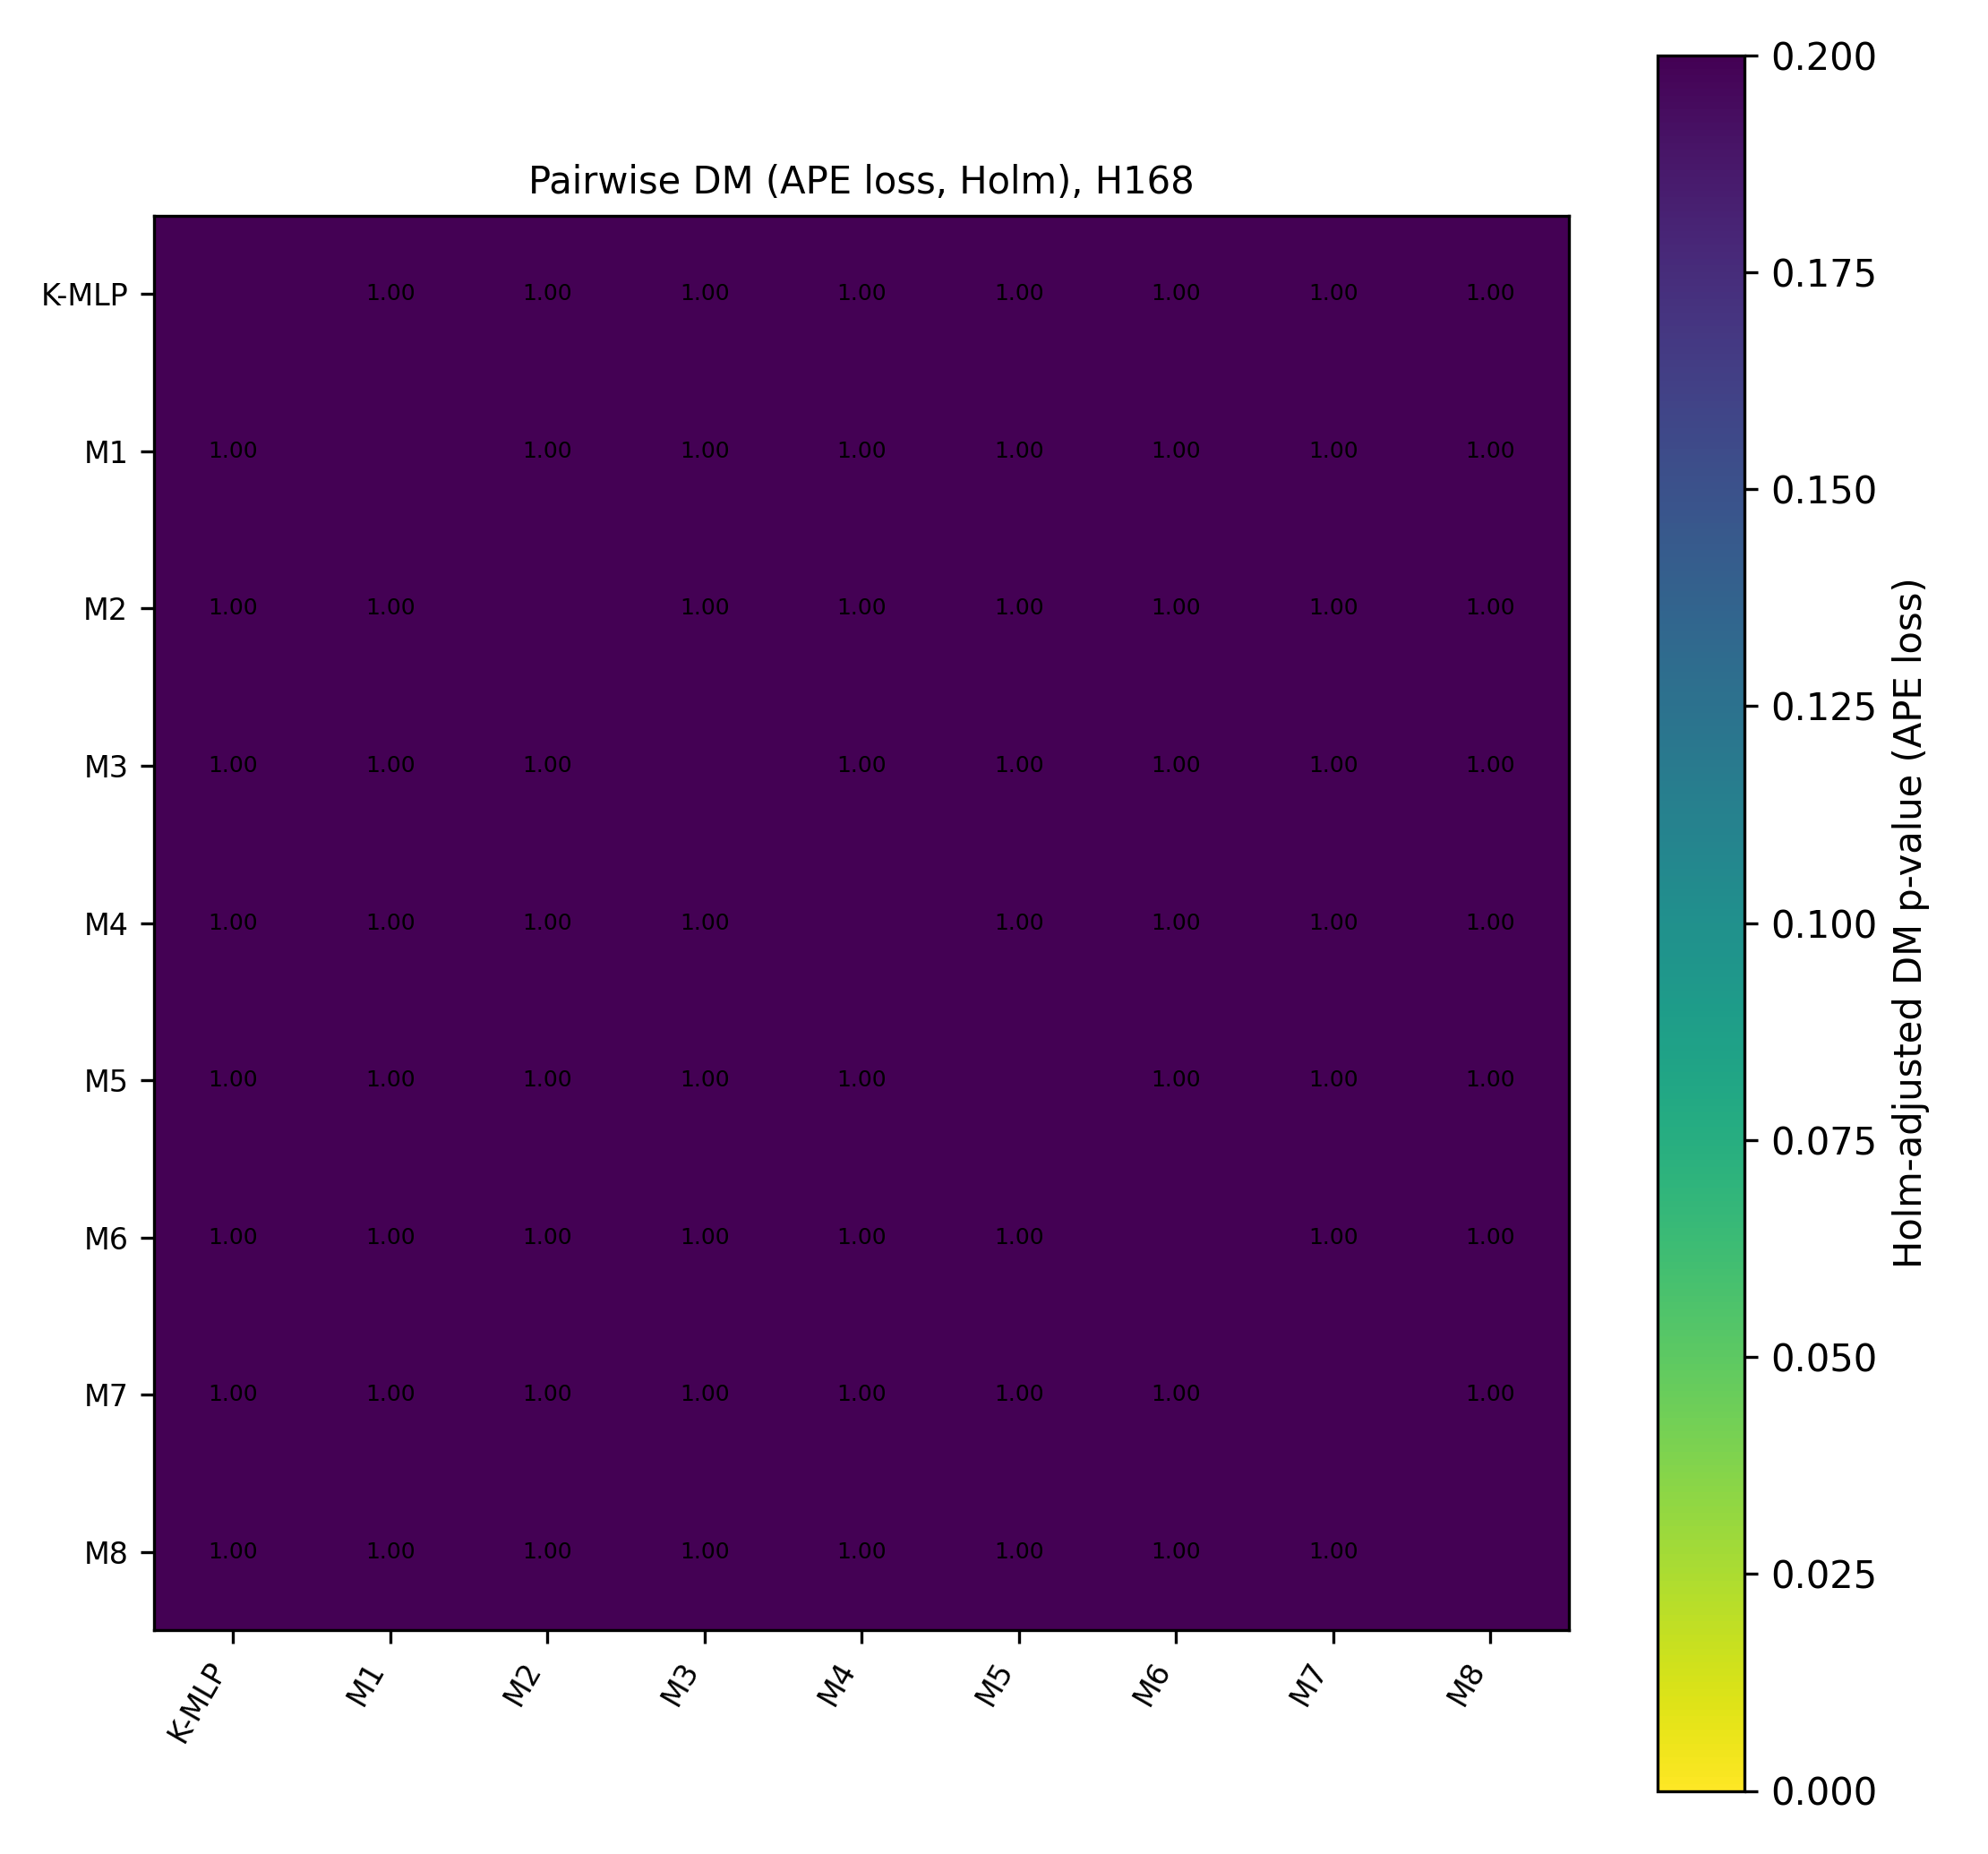

/kaggle/working/results_v3/figures/dm_pvalues_H24.png


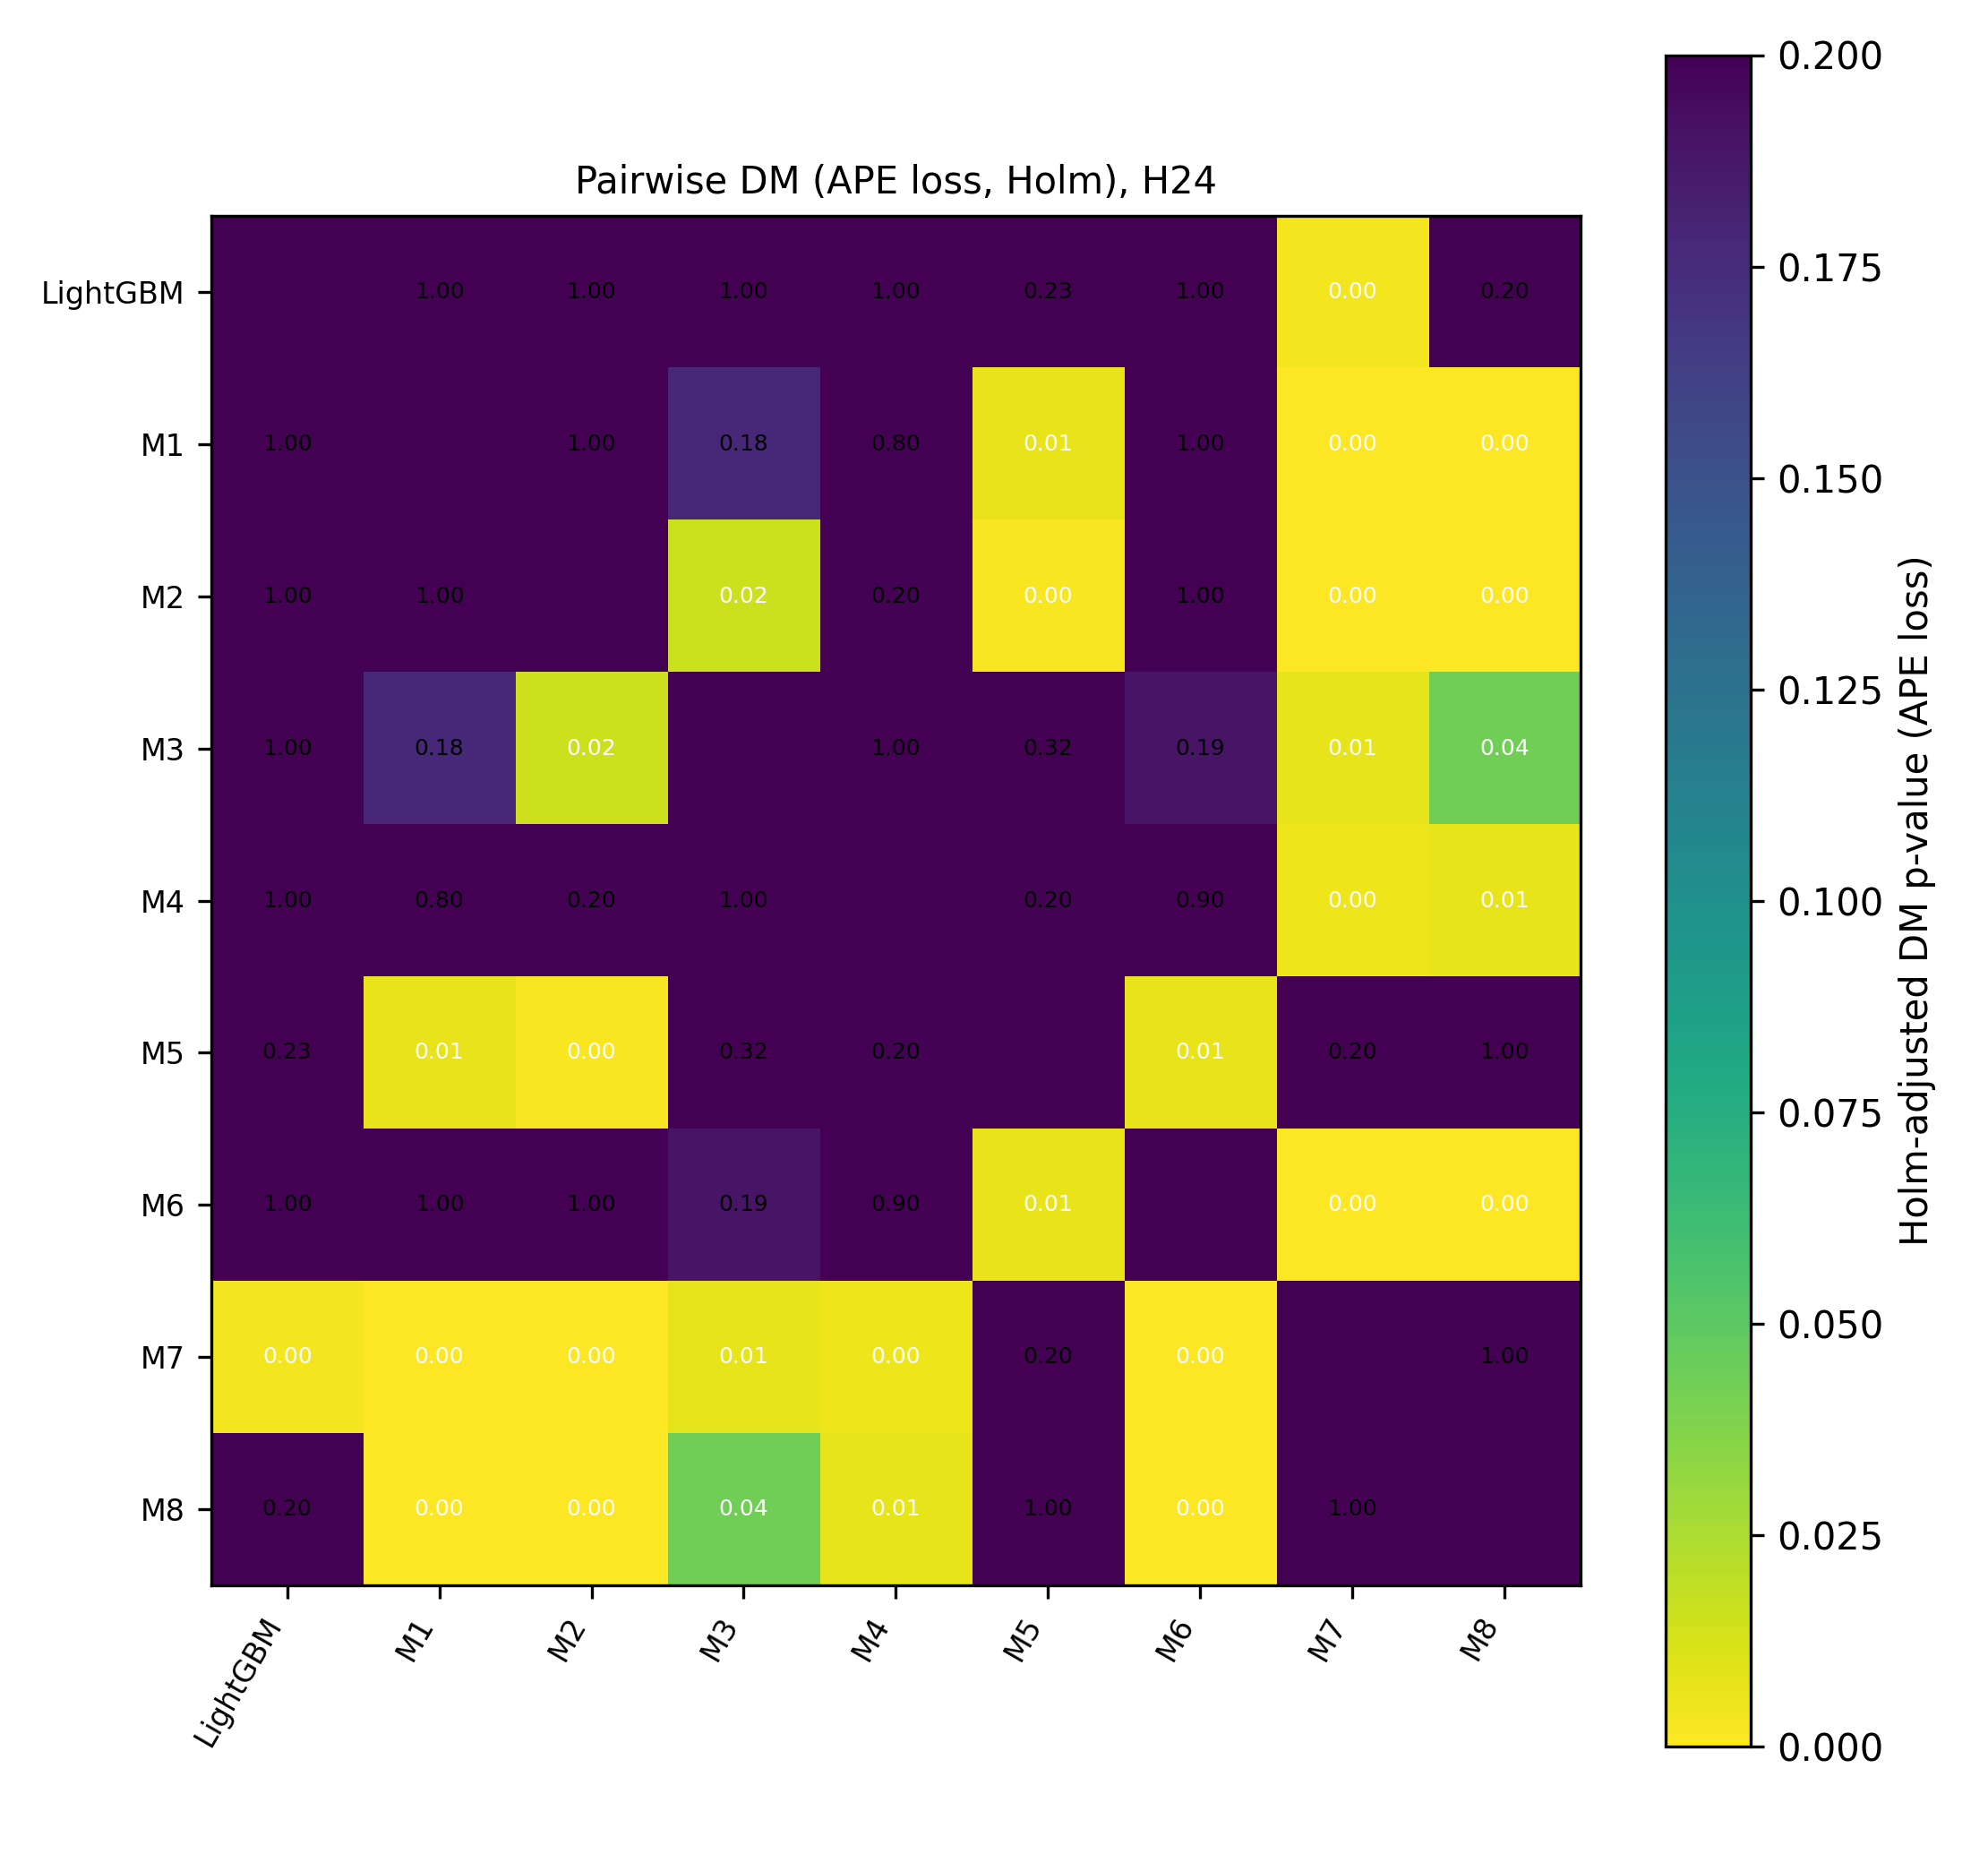

/kaggle/working/results_v3/figures/dm_pvalues_H720.png


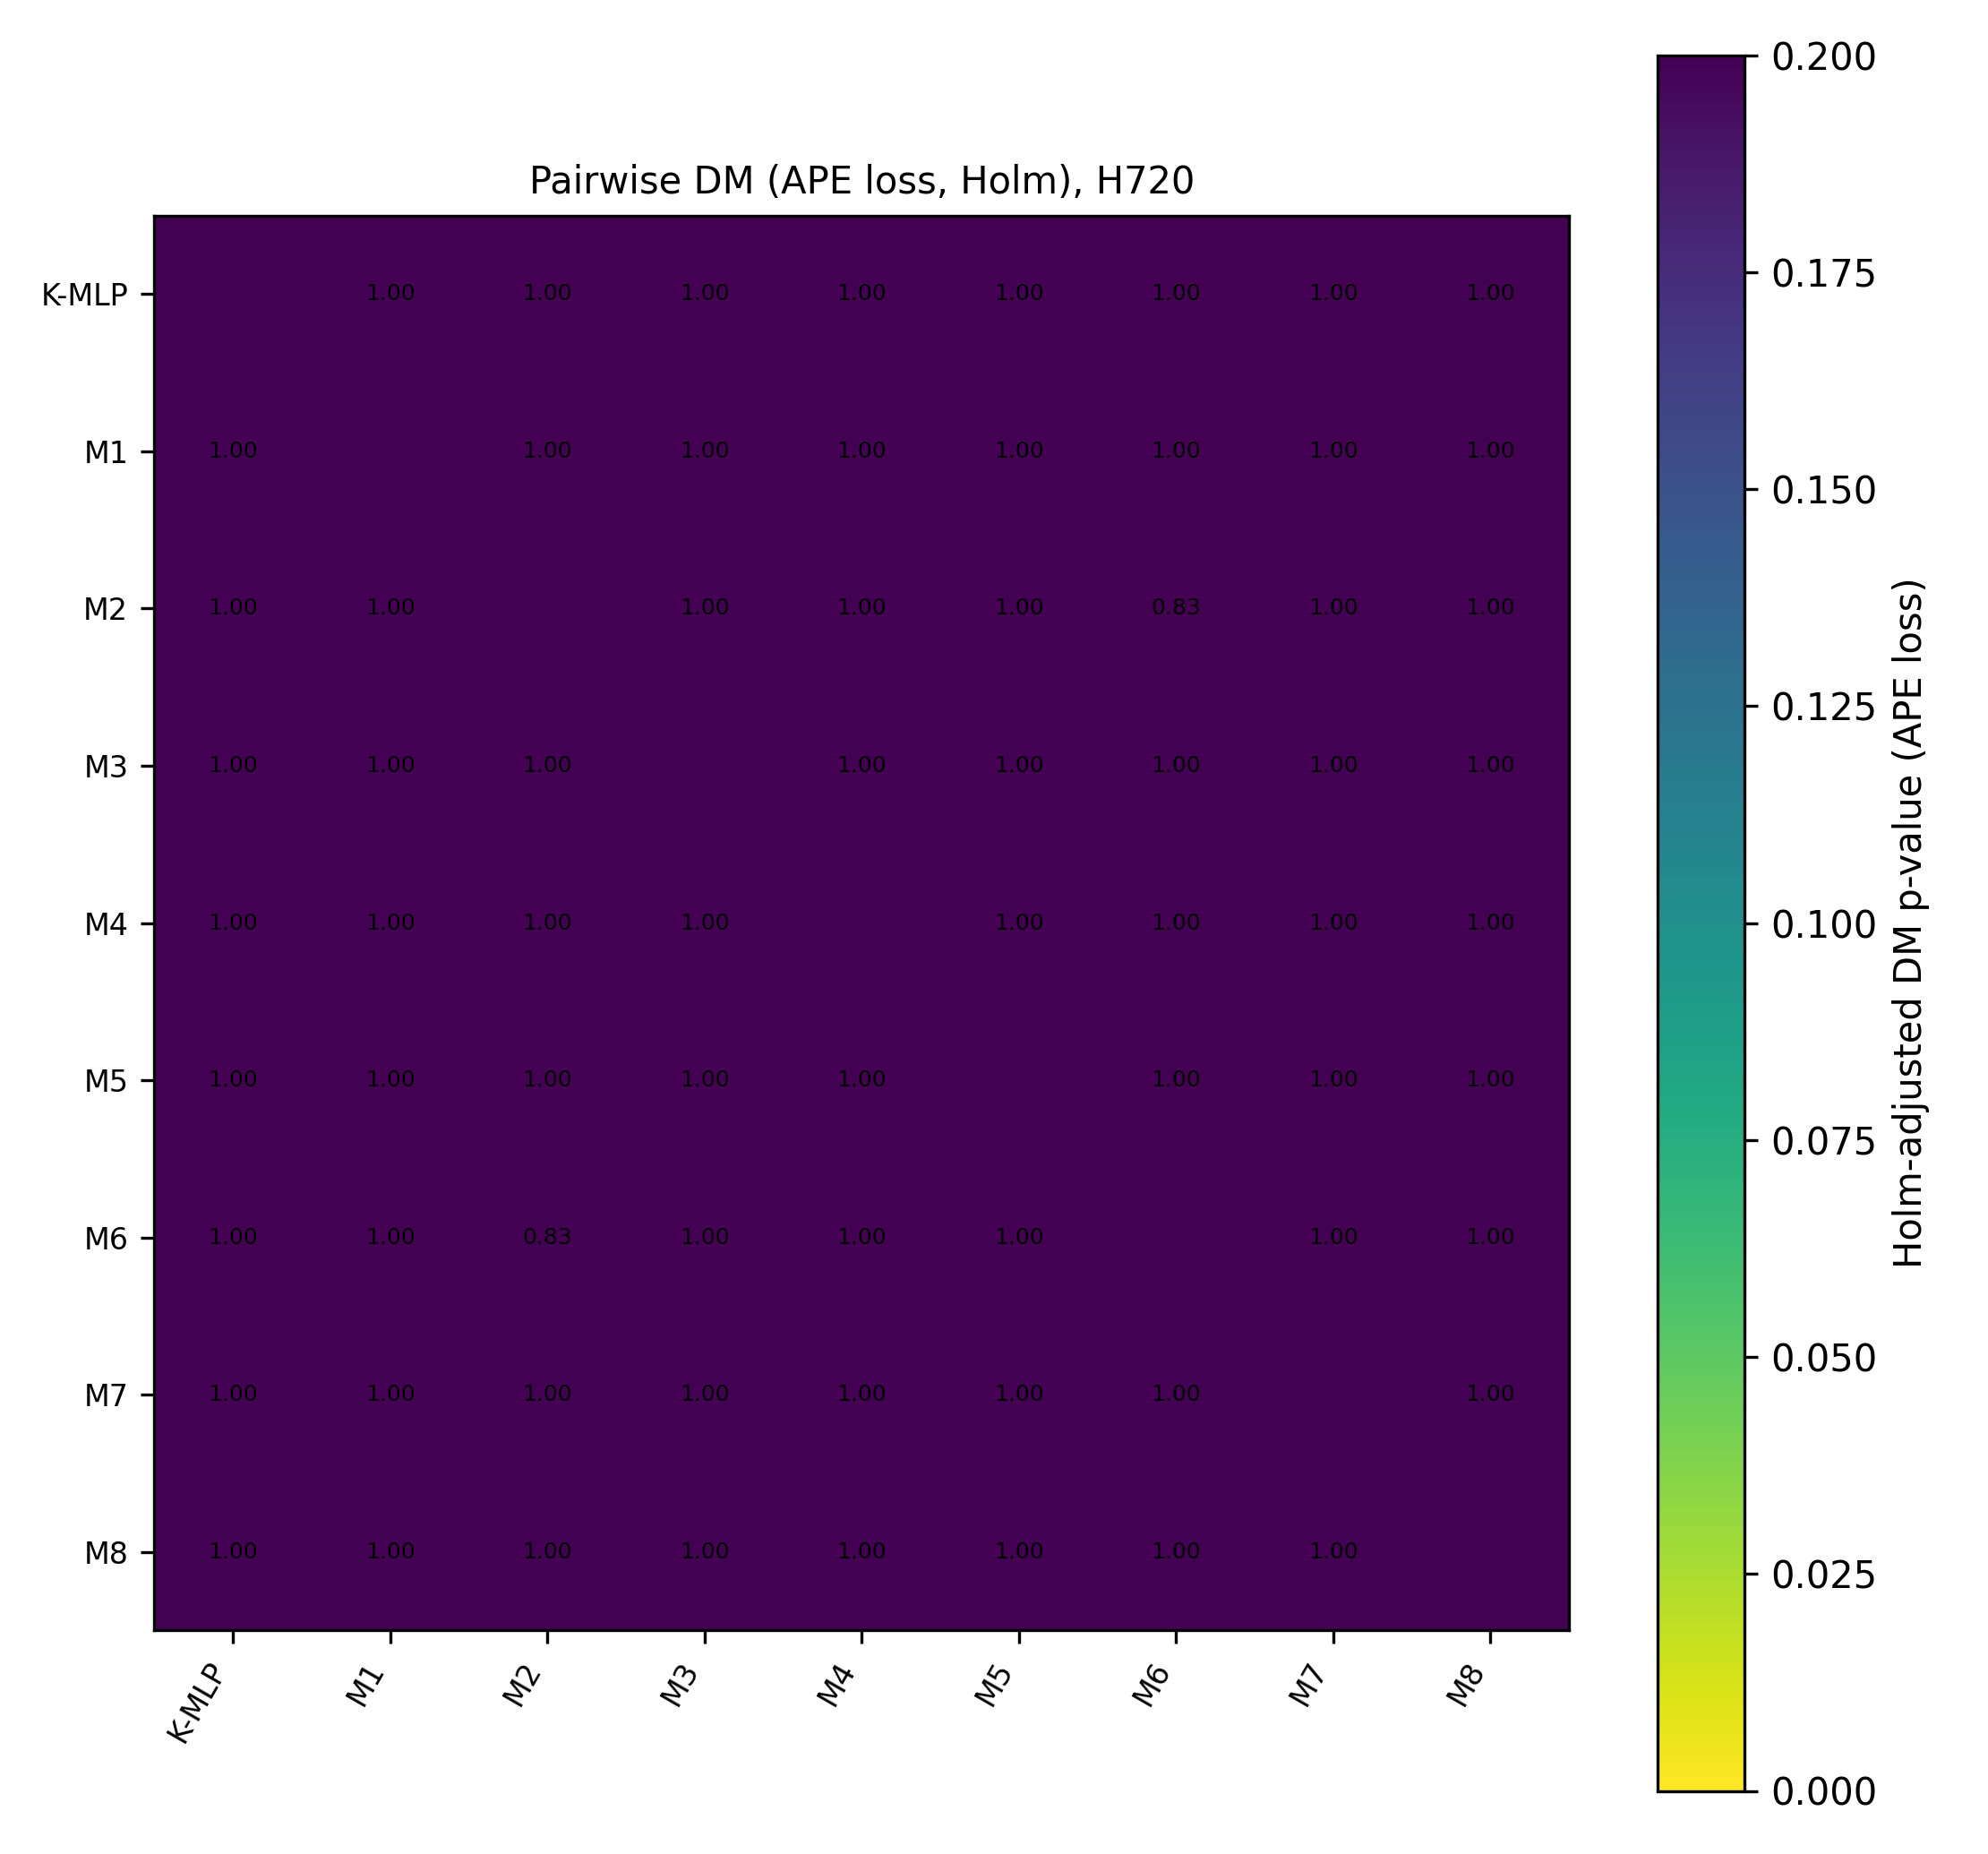

/kaggle/working/results_v3/figures/dm_pvalues_HDA.png


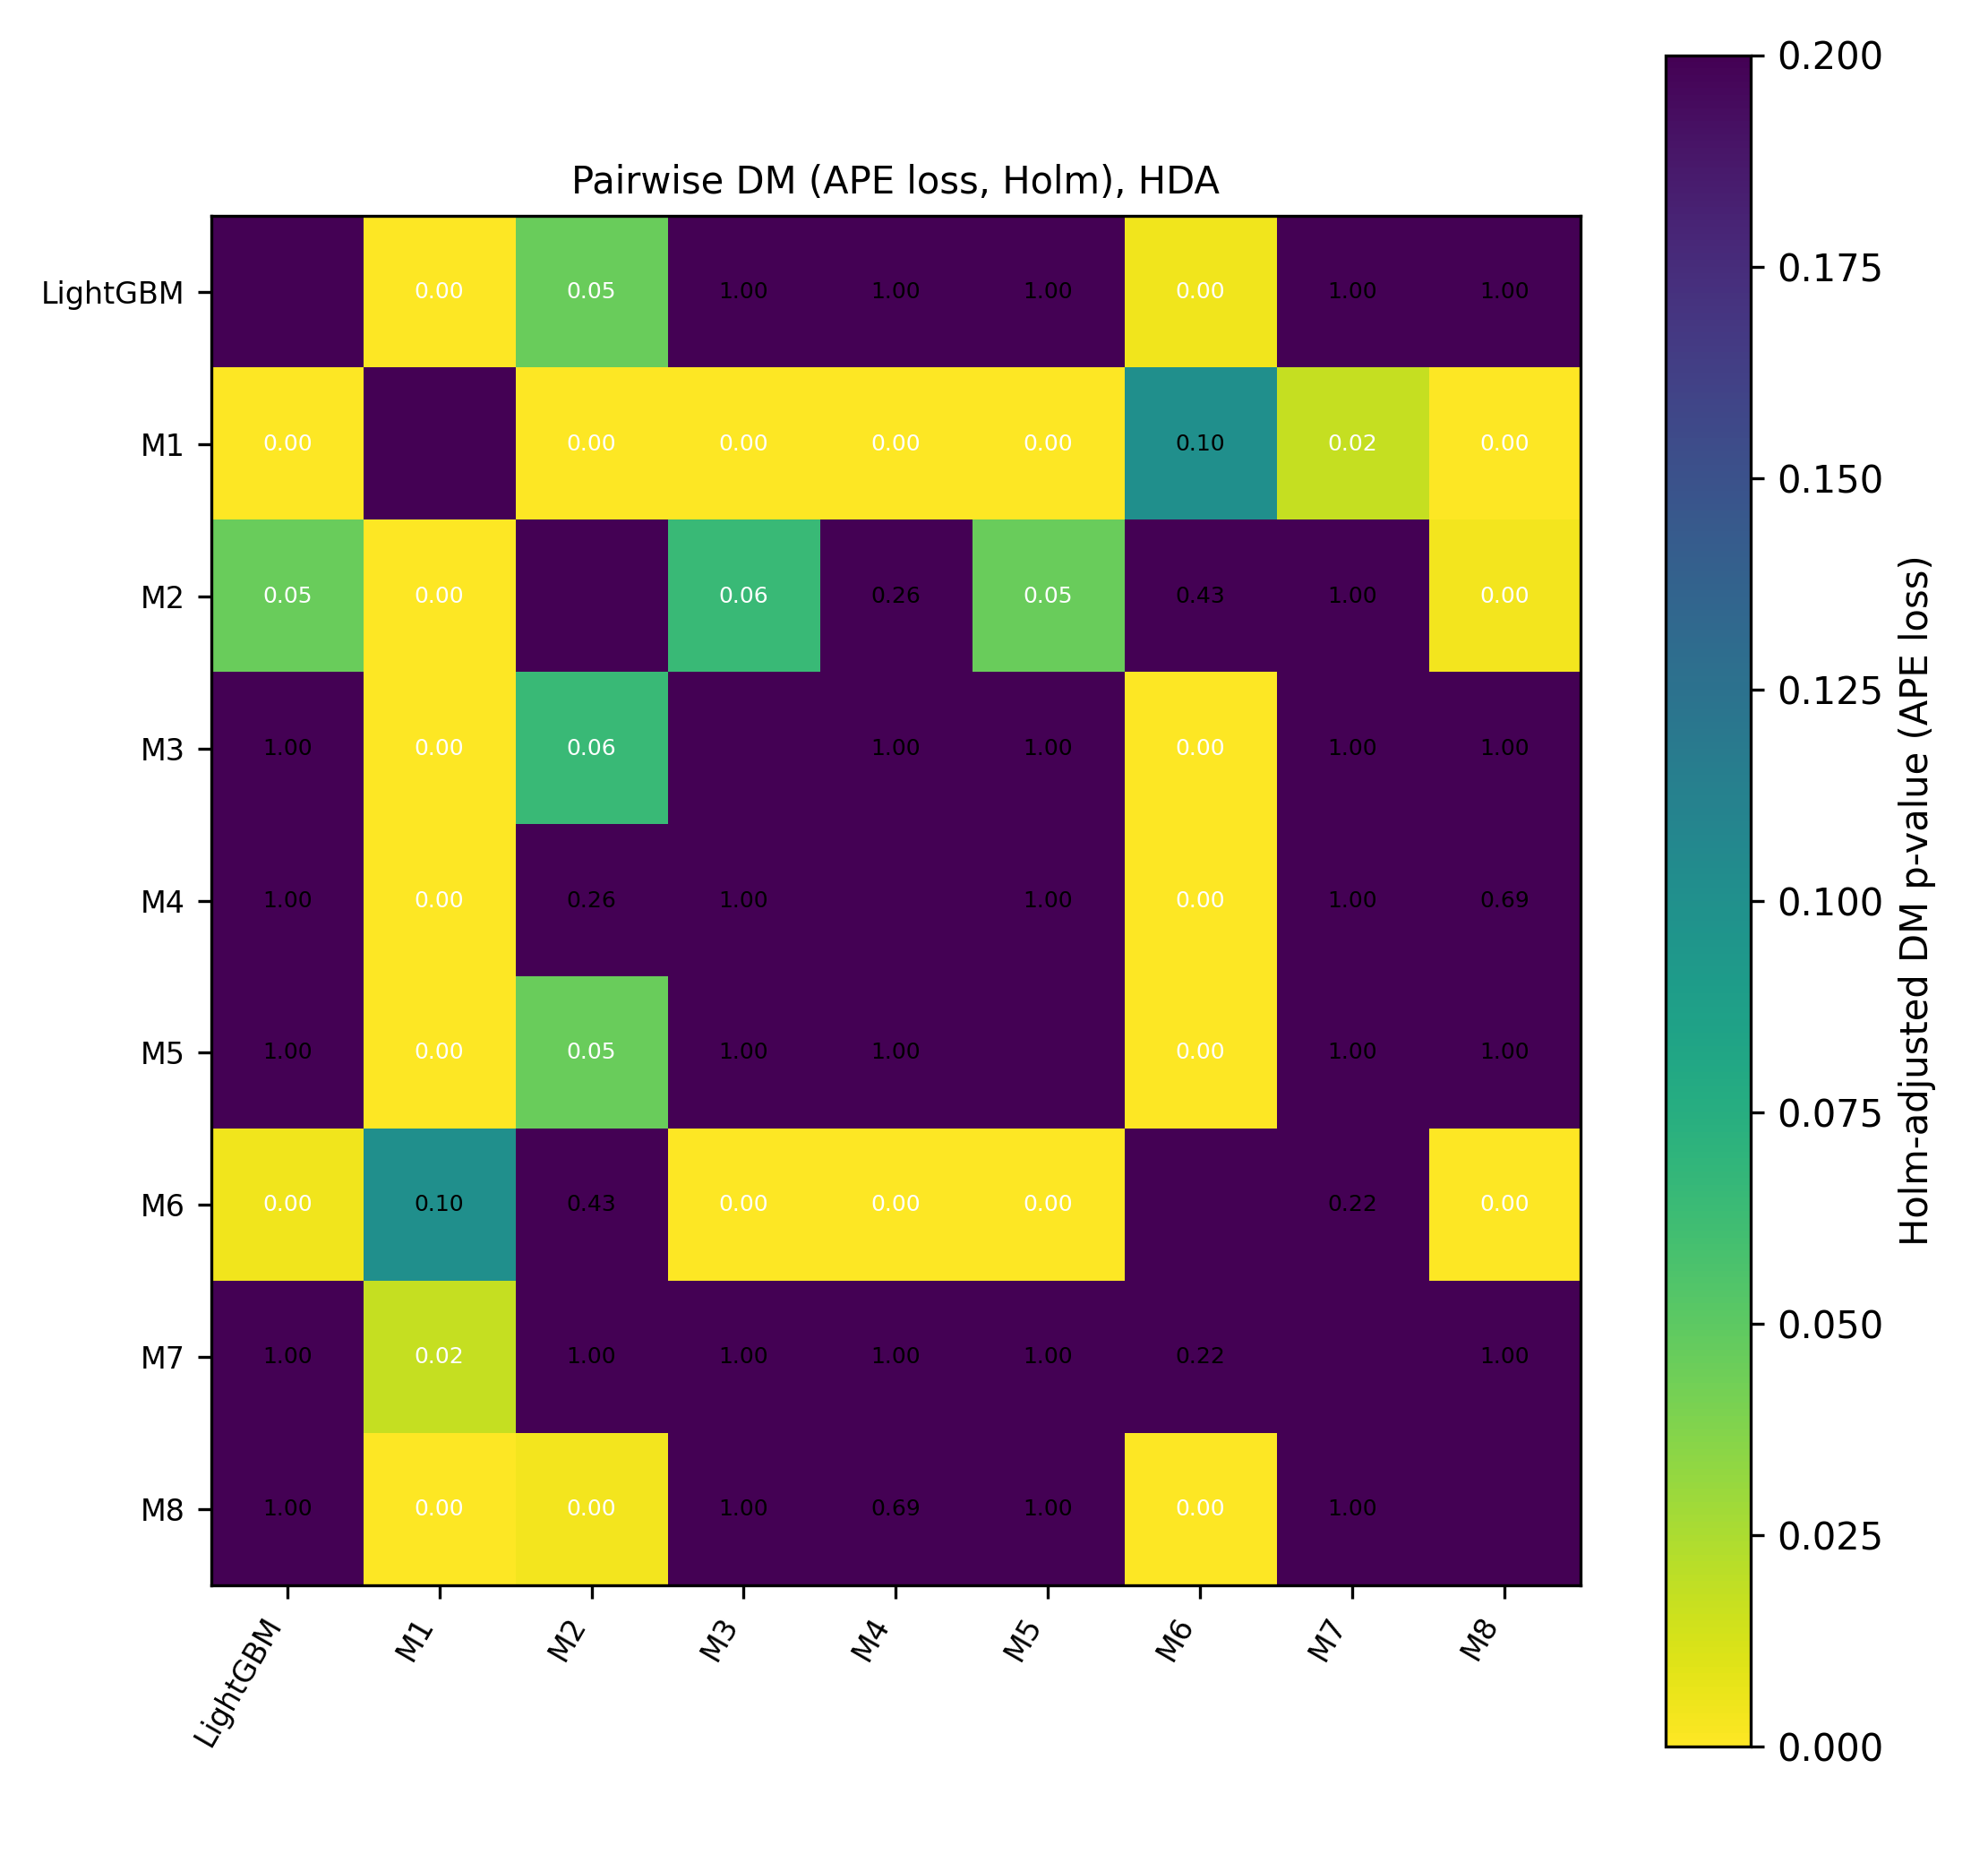

/kaggle/working/results_v3/figures/first_week_H168_M3.png


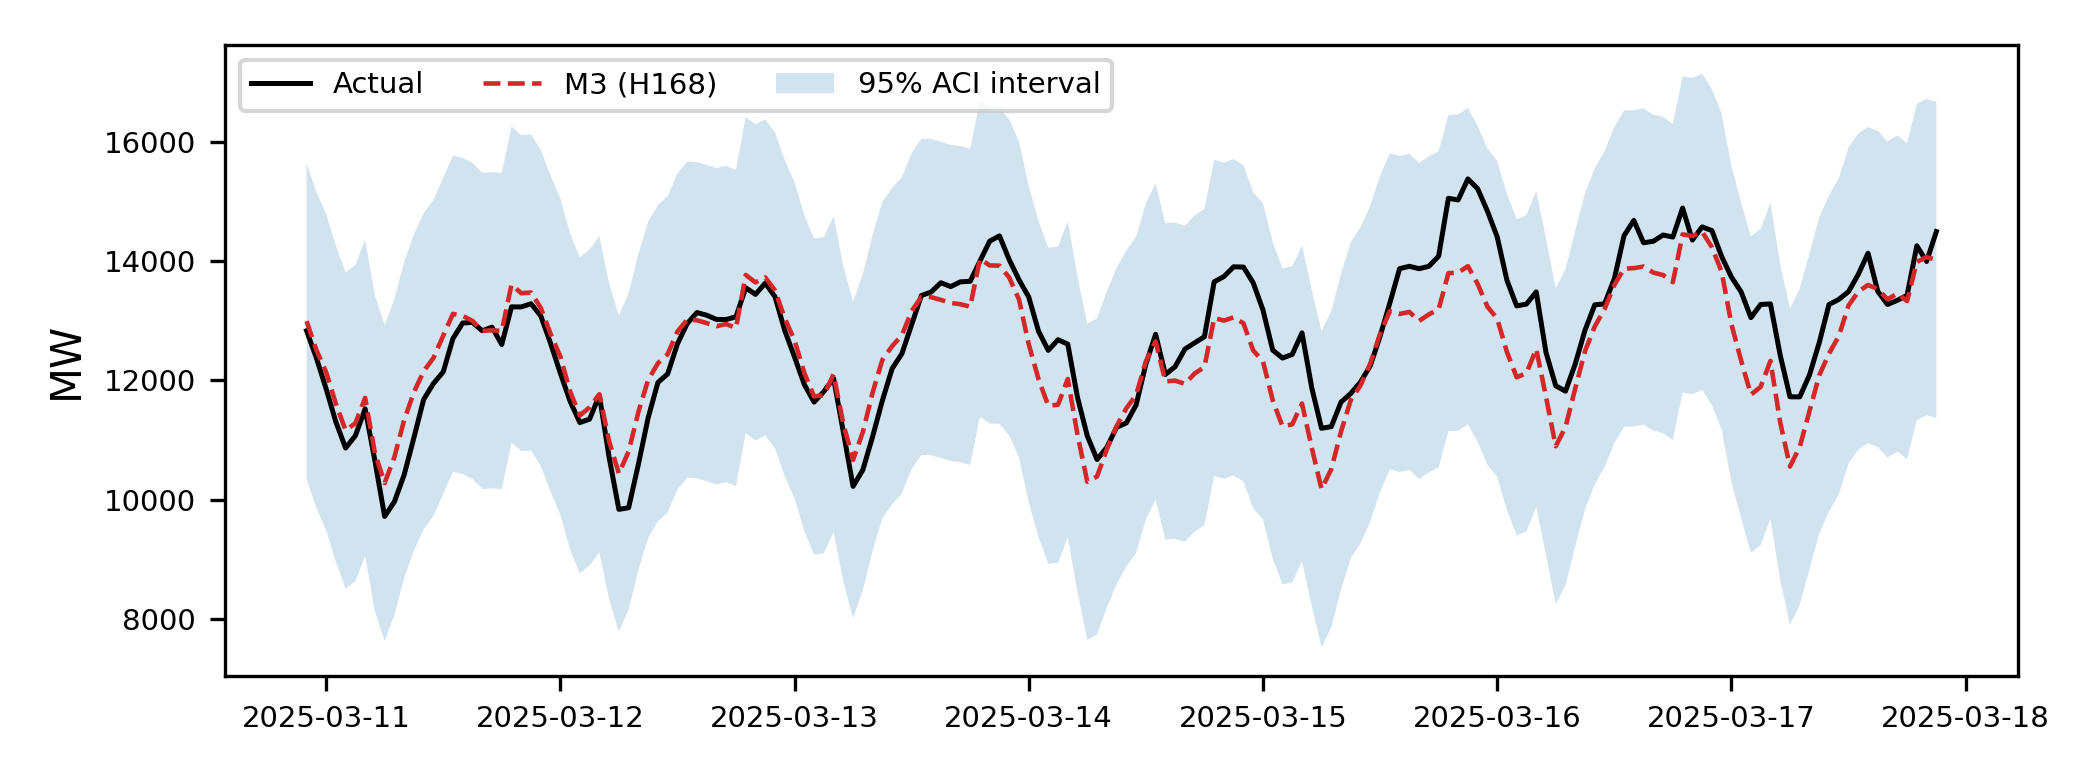

/kaggle/working/results_v3/figures/first_week_H24_M7.png


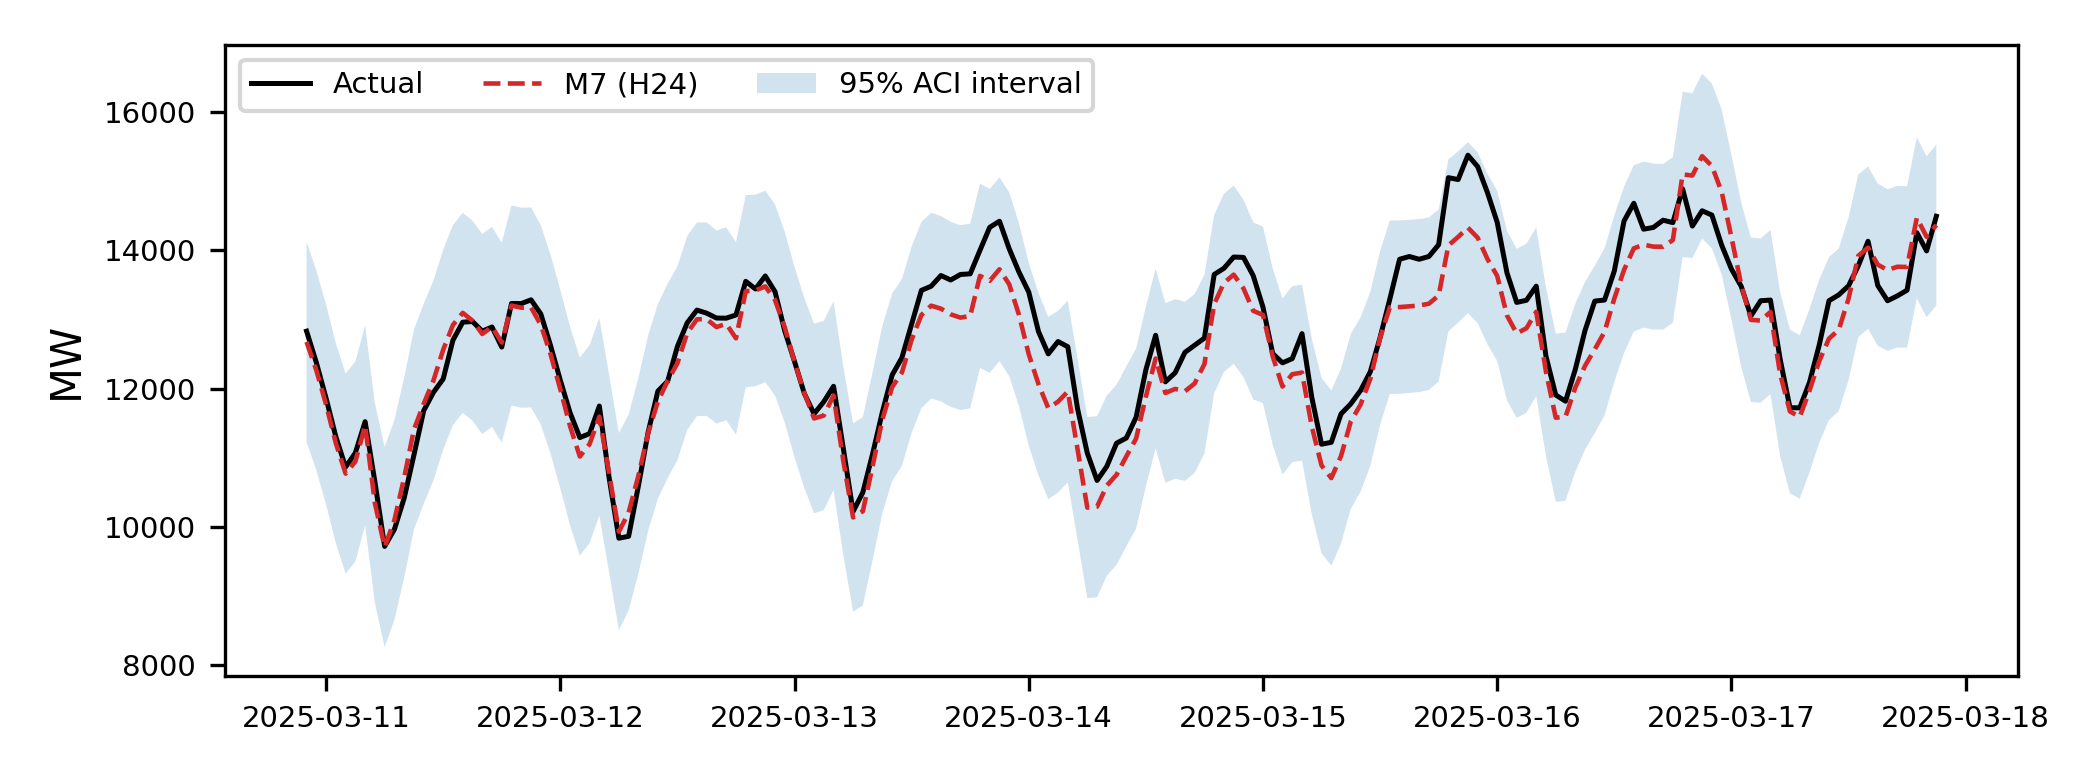

/kaggle/working/results_v3/figures/first_week_H720_M6.png


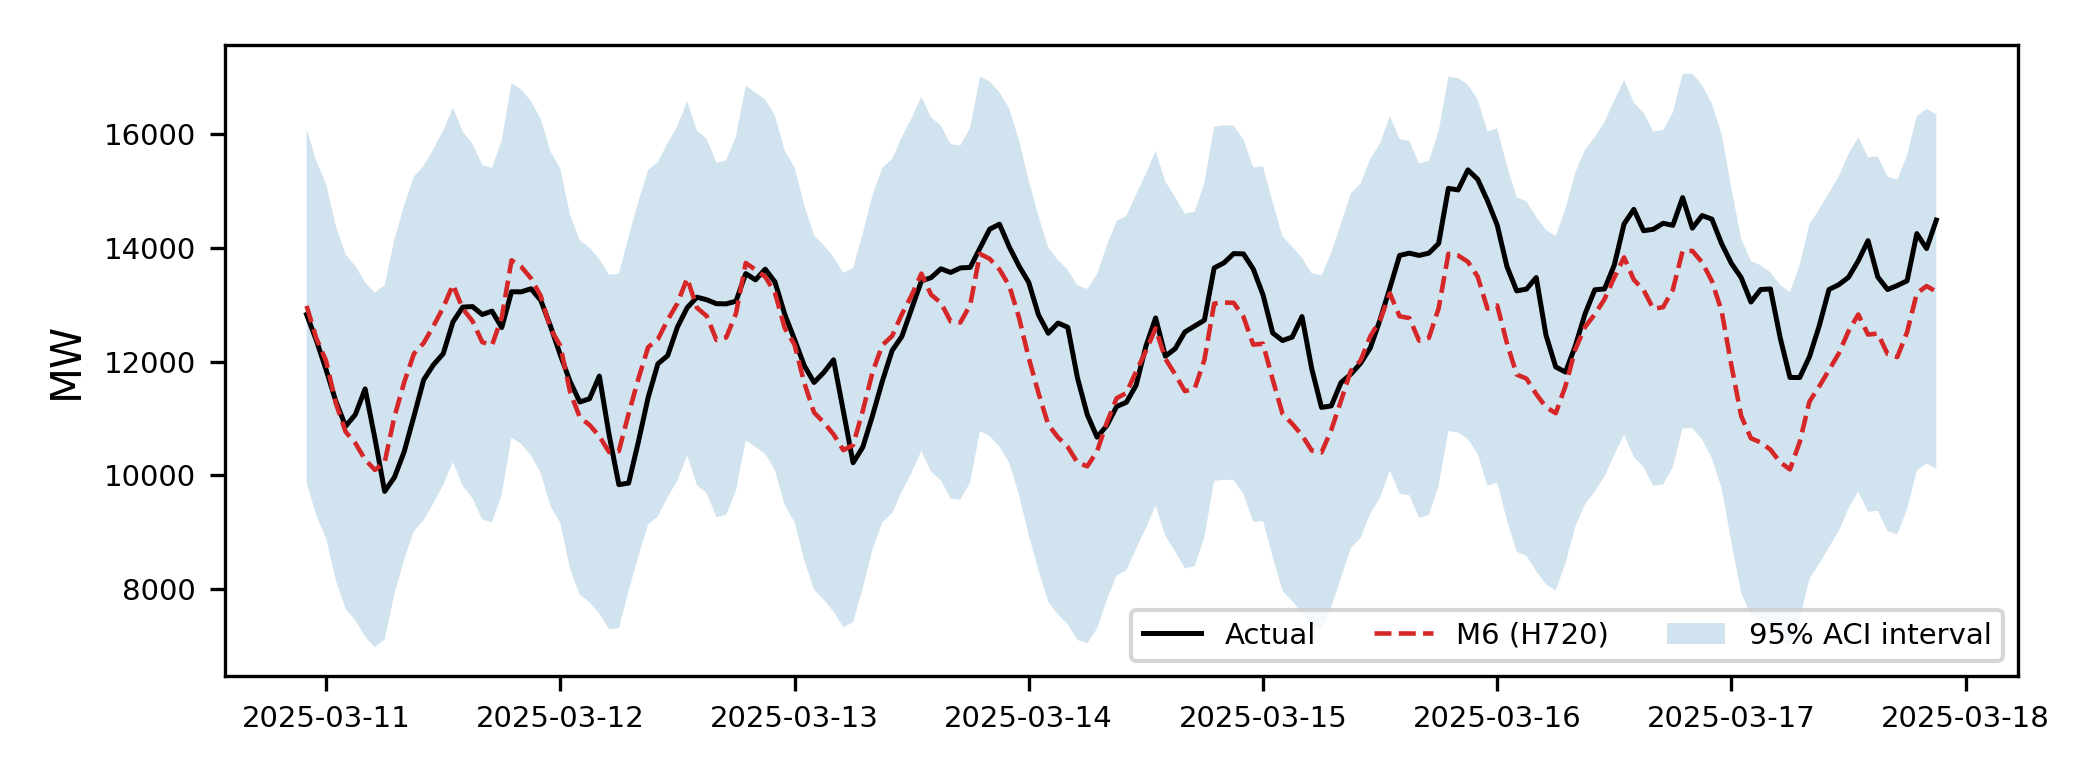

/kaggle/working/results_v3/figures/first_week_HDA_M8.png


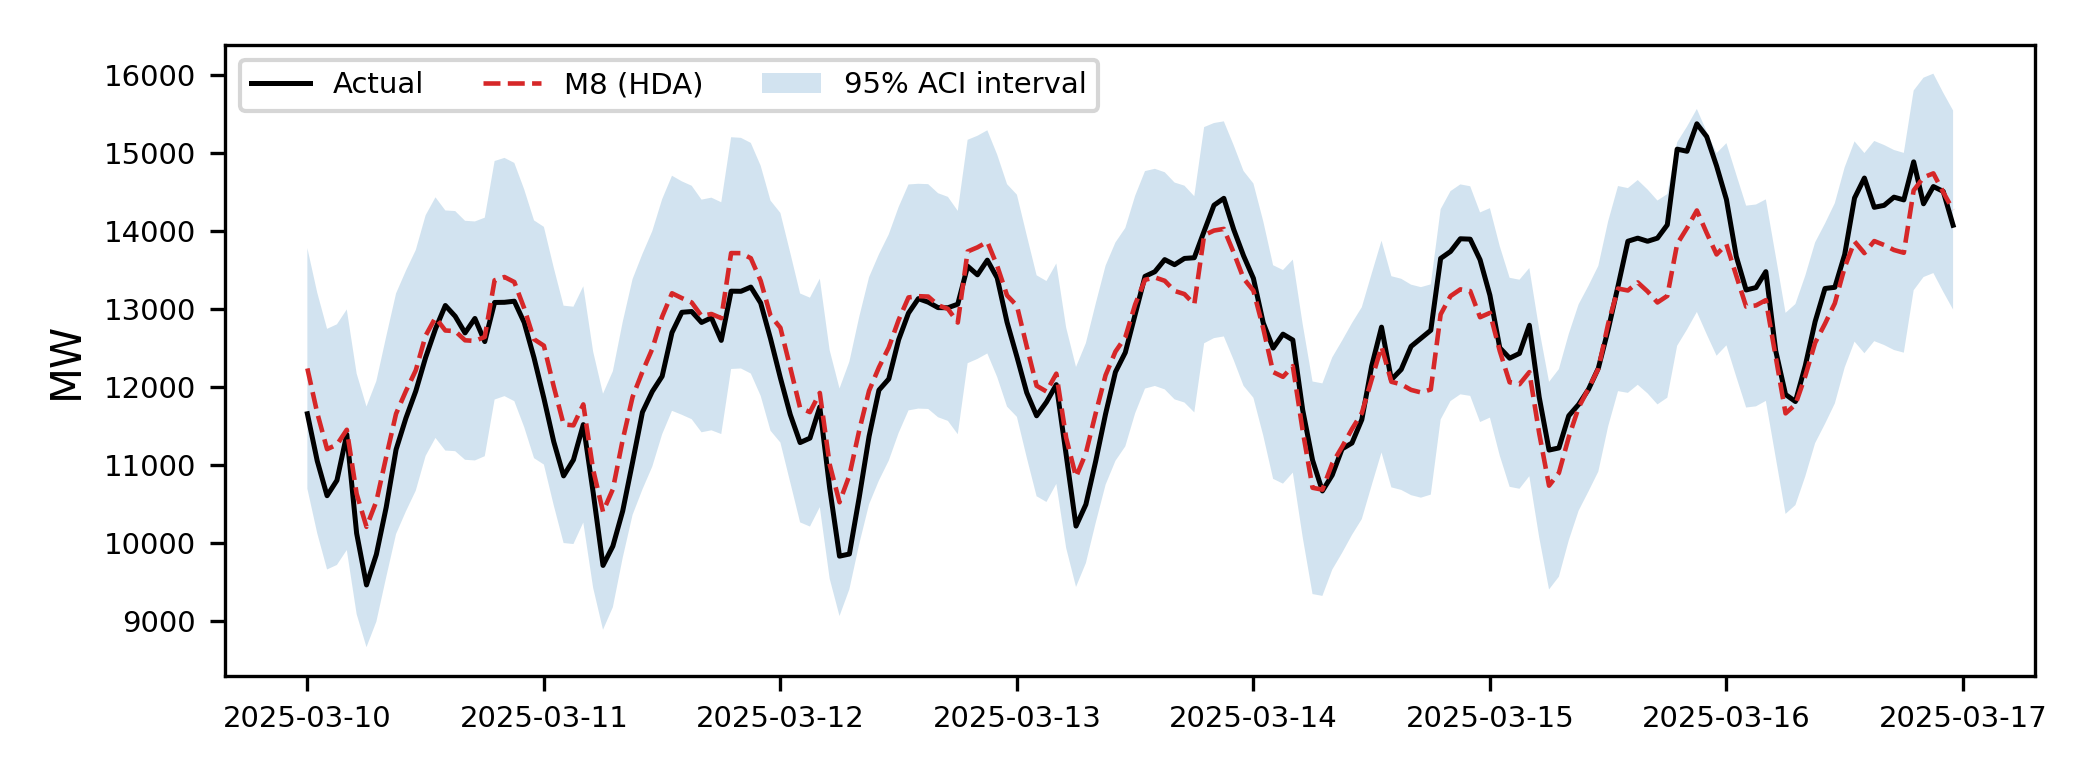

/kaggle/working/results_v3/figures/grouped_importance_best_models.png


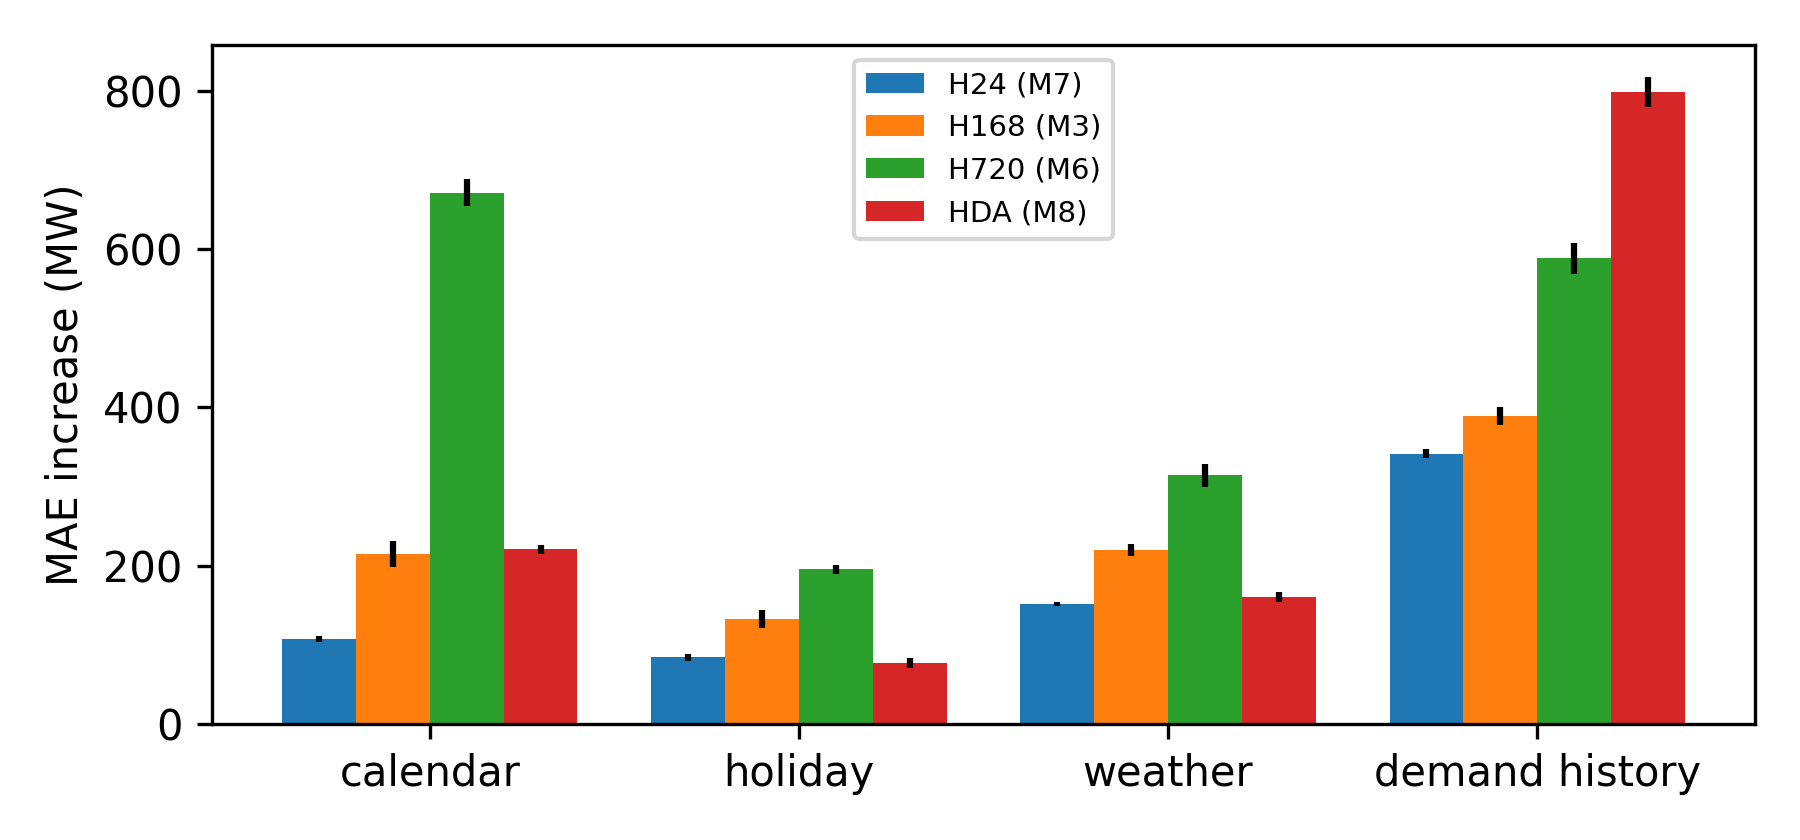

/kaggle/working/results_v3/figures/monthly_mape_best.png


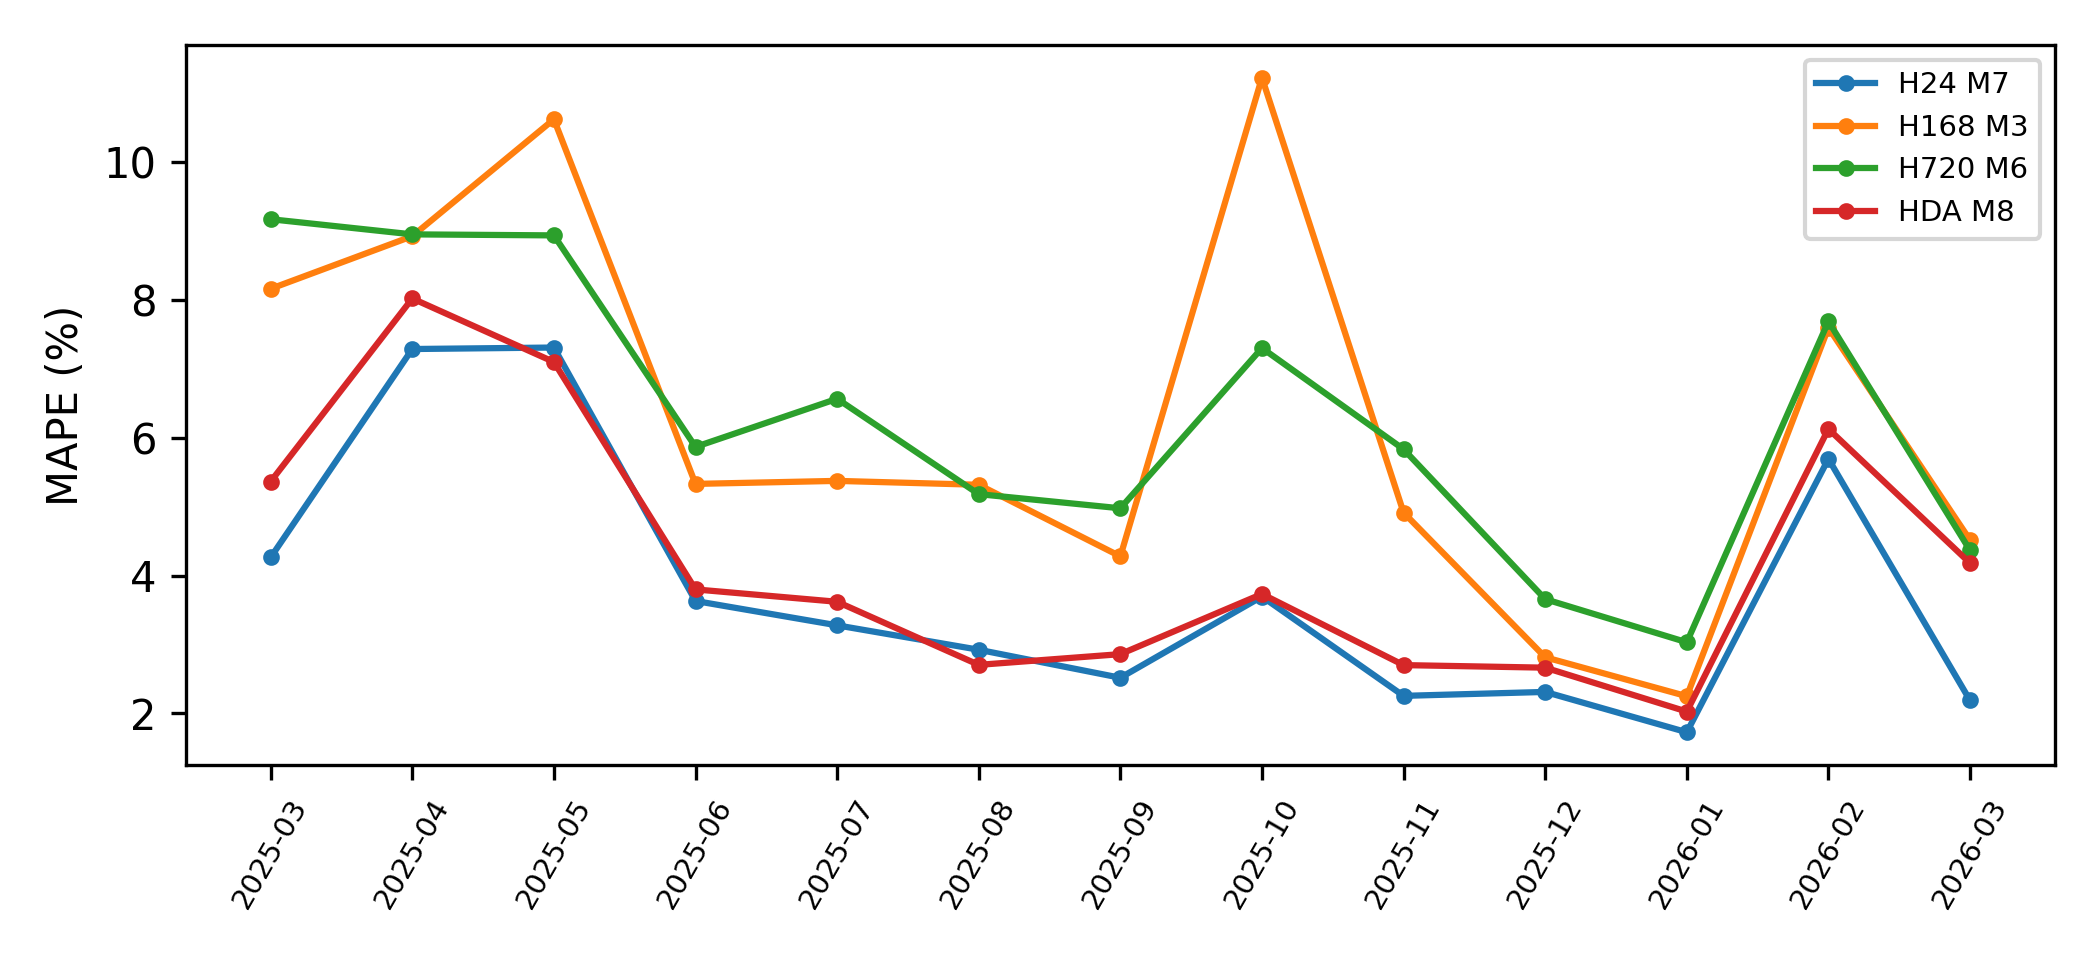

In [15]:
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(f"{OUT_ROOT}/figures/*.png")):
    print(f)
    display(Image(f, width=700))